In [1]:
import sys
sys.path.insert(0, '/Users/alnoor.ismail/Downloads/eng2040_assignment_01 5')
from pipeline_support import NotebookObserver
_pipeline_observer = NotebookObserver('/Users/alnoor.ismail/Downloads/eng2040_assignment_01 5/outputs/.assignment1.run-qjiv6vuy/calibration/pilot', '/Users/alnoor.ismail/Downloads/eng2040_assignment_01 5/outputs/.assignment1.run-qjiv6vuy/.temporary/pilot', '/Users/alnoor.ismail/Downloads/eng2040_assignment_01 5/outputs/.assignment1.run-qjiv6vuy/calibration/pilot/marketplace.sqlite')

# ENG2040 — Assignment 1

**Alnoor Ismail**

This notebook assembles marketplace order data, audits data quality, explores late deliveries, and prepares features and labels for a future model.

**Saving outputs**

Running these notebook cells keeps the tables in memory. To execute the analysis and save its tables, charts, schemas, and audits, run this command from the project folder:

```sh
python run_pipeline.py
```

The pipeline exports these tables automatically:

- `source_items` → `outputs/assignment1/stages/08_cleaning/source_items.csv`
- `state_sensitivity` → `outputs/assignment1/stages/08_cleaning/state_sensitivity.csv`
- `imputation_values` → `outputs/assignment1/stages/16_final_features/imputation_values.csv`

The command saves a separately executed notebook in the same output folder. See `README.md` for the other exports and loading instructions.

**Contents**

- [Setup](#setup)
- [Part 1: Data Loading and Assembly](#part-1)
- [Part 2: Data Quality and Cleaning](#part-2)
- [Part 3: Exploratory Analysis](#part-3)
- [Part 4: Feature Engineering](#part-4)
- [Resource Summary](#resources)


<a id="setup"></a>

## Setup


### Importing Libraries

In [2]:
_pipeline_observer.start('01_setup')

In [3]:
import sqlite3
import pandas as pd
import numpy as np
import time
import tracemalloc
import matplotlib.pyplot as plt
import seaborn as sns
import os
import subprocess



Matplotlib is building the font cache; this may take a moment.


### Function helpers

In [4]:
# ---------- Resource measurement (runtime and peak traced Python memory per pipeline step)
resource_log = []

def start_step():
    if tracemalloc.is_tracing():
        tracemalloc.stop()
    tracemalloc.start()
    return time.perf_counter()

def end_step(step, t0):
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    resource_log.append({'Step': step, 'Runtime_s': round(time.perf_counter() - t0, 3),
                         'Peak_traced_MiB': round(peak / 2**20, 2)})

# ---------- Local timestamp parser: explicit formats, nothing guessed
TIMESTAMP_FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%Y-%m-%d',
                     '%d/%m/%Y %H:%M:%S', '%d/%m/%Y %H:%M', '%d/%m/%Y']   # Brazilian data: day first

def parse_local_timestamp(col):
    """Try each known format in turn; values matching none (e.g. 30 Feb) stay missing."""
    s = col.astype('string').str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    for fmt in TIMESTAMP_FORMATS:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors='coerce'))
    return out

# ---------- Uncertainty helpers used in Part 3
# A late rate gets a 95% Wilson interval: given k late orders out of n, the range of true
# rates that could plausibly have produced that count. Two rates differ when their
# intervals do not overlap (a gap between them); overlapping intervals mean no clear
# evidence of a difference, which is not proof that there is none.
Z95 = 1.96   # 95% coverage

def wilson_ci(late, n, z=Z95):
    """95% Wilson interval for late / n (works on single numbers and on columns)."""
    late, n = np.asarray(late, float), np.asarray(n, float)
    p = late / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def mean_ci(values, z=Z95):
    """95% confidence interval for a mean: the mean plus or minus 1.96 standard errors."""
    v = pd.Series(values, dtype=float).dropna()
    se = v.std(ddof=1) / np.sqrt(len(v))
    return v.mean() - z * se, v.mean() + z * se

def rate_table(data, group_col, label_col=None):
    """Orders, late orders, late rate and 95% Wilson interval per group."""
    label_col = label_col or target_col
    t = (data.groupby(group_col, dropna=False, observed=True)[label_col]
             .agg(Total_Orders='count', Late_Orders='sum', Late_Rate='mean').reset_index())
    t['CI_Lower'], t['CI_Upper'] = wilson_ci(t['Late_Orders'], t['Total_Orders'])
    few = (t['Late_Orders'] < 5) | (t['Total_Orders'] - t['Late_Orders'] < 5)
    t['CI_Note'] = np.where(few, 'too few events: interval suppressed', '')
    t.loc[few, ['CI_Lower', 'CI_Upper']] = np.nan
    return t

def compare_rates(name, label_a, late_a, n_a, label_b, late_b, n_b):
    """Compare two late rates by their 95% Wilson intervals: a gap means the rates differ."""
    lo_a, hi_a = wilson_ci(late_a, n_a)
    lo_b, hi_b = wilson_ci(late_b, n_b)
    gap = lo_a > hi_b or lo_b > hi_a
    result = (f"{label_a} {late_a / n_a:.1%} [{lo_a:.1%}, {hi_a:.1%}], n={int(n_a):,} vs "
              f"{label_b} {late_b / n_b:.1%} [{lo_b:.1%}, {hi_b:.1%}], n={int(n_b):,}")
    finding = 'gap: rates differ' if gap else 'overlap: no clear difference'
    print(f"{name}: {result} -> {finding}")
    return {'Comparison': name, 'Result': result, 'Finding': finding}

def compare_to_overall(t, name, overall=None):
    """Count the groups whose whole 95% interval lies above or below the overall rate."""
    if overall is None:
        overall = t['Late_Orders'].sum() / t['Total_Orders'].sum()
    shown = t['CI_Lower'].notna()
    above = int((shown & (t['CI_Lower'] > overall)).sum())
    below = int((shown & (t['CI_Upper'] < overall)).sum())
    result = (f"{len(t)} groups, overall rate {overall:.1%}: {above} wholly above, {below} wholly below, "
              f"{int(shown.sum()) - above - below} overlapping, {int((~shown).sum())} too small")
    finding = 'gap: rates differ' if above or below else 'overlap: no clear difference'
    print(f"{name}: {result} -> {finding}")
    return {'Comparison': name, 'Result': result, 'Finding': finding}

comparisons = []   # every comparison is collected here and shown at the end of Part 3

def plot_rates(t, x_col, title, xlabel, figsize=(9, 4)):
    """Bar chart of late rates with 95% interval error bars and the overall rate as a dashed line."""
    t = t.reset_index(drop=True).copy()
    labels = t[x_col].astype(str).tolist()
    overall = df_labeled[target_col].mean()
    yerr = [(t['Late_Rate'] - t['CI_Lower']).clip(lower=0).fillna(0), (t['CI_Upper'] - t['Late_Rate']).clip(lower=0).fillna(0)]
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(labels, t['Late_Rate'], yerr=yerr, capsize=4, color='#2b5c8f', ecolor='grey')
    ax.axhline(overall, ls='--', color='#d95f02', lw=1.2, label=f'Overall rate ({overall:.1%})')
    for i, r in enumerate(t.itertuples()):
        top = r.CI_Upper if pd.notna(r.CI_Upper) else r.Late_Rate
        note = '*' if r.CI_Note else ''
        ax.text(i, top + 0.004, f'{r.Late_Rate:.1%}{note}\nn={r.Total_Orders:,}',
                ha='center', va='bottom', fontsize=8)
    ax.set_ylim(0, max(t['CI_Upper'].fillna(t['Late_Rate']).max(), overall) * 1.3)
    if t['CI_Note'].ne('').any():
        xlabel += '\n* Fewer than 5 events or non-events; interval suppressed.'
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel('Proportion Delivered Late')
    ax.legend(loc='upper right'); plt.tight_layout(); plt.show()


In [5]:
_pipeline_observer.end('01_setup', globals())

<a id="part-1"></a>

## Part 1: Data Loading and Assembly

Inspect the source tables, check aggregation requirements, verify record preservation, and assemble the order-level dataset.

### 1.1 Database Tables and Row Counts

Inspect sample records and count the rows in each source table.

In [6]:
_pipeline_observer.start('02_inspection')

In [7]:
db_path = "marketplace.sqlite"

# Set up database if missing
if not os.path.exists(db_path) and os.path.exists("setup_db.py"):
    subprocess.run(["python3", "setup_db.py"], check=True)

# Connect, inspect tables, schemas, and samples
with sqlite3.connect(db_path) as conn:
    tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn)['name']
    
    for table in tables:
        print(f"\nTable: {table}")
        #display(pd.read_sql(f"PRAGMA table_info('{table}');", conn))
        display(pd.read_sql(f"SELECT * FROM '{table}' LIMIT 2;", conn))


Table: category_translation


,product_category_name,product_category_name_english
0,agro_industria_e_comercio,agro_industry_and_commerce
1,alimentos,food



Table: customers


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,00114026c1b7b52ab1773f317ef4880b,f4dc0a81a11d3d270ccf5a9c4b5b187b,22470,rio de janeiro,RJ
1,0012a5c13793cf51e253f096a7e740dd,48efc7def11f9a644e1993a3d97361d2,20011,rio de janeiro,RJ



Table: order_items


...

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,0045e3085f083f0f38d24bb3f22e6593,eb729faa993caad20442243265804a7c,DELIVERED,2017-08-10 16:13:36,2017-08-11 07:15:16,2017-08-16 18:27:40,2017-08-29 20:03:08,2017-08-30 00:00:00
1,006df90050498994d670b40da4651d22,5c94f28f54aa13e14aaf67039511f318,canceled,2018-08-13 13:59:20,2018-08-13 14:15:12,2018-08-14 14:43:00,2018-08-15 22:18:36,2018-08-17 00:00:00



Table: products


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,007c63ae4b346920756b5adcad8095de,utilidades_domesticas,48,808,1,2800.0,30.0,30.0,30.0
1,00905d58c87afcbce21420b3712cacaa,CAMA_MESA_BANHO,59,253,1,3875.0,46.0,12.0,43.0



Table: sellers


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,001cca7ae9ae17fb1caed9dfb1094831,29156,cariacica,es
1,002100f778ceb8431b7a1020ff7ab48f,NaN,franca,sp


In [8]:
conn = sqlite3.connect(db_path)

# Count rows in each table to see discrepancies
for t in tables:
    count = pd.read_sql(f"SELECT COUNT(*) FROM {t}", conn).iloc[0, 0]
    print(f"Table '{t}': {count:,} rows")

conn.close()

Table 'category_translation': 73 rows
Table 'customers': 1,922 rows
Table 'order_items': 2,270 rows
Table 'order_payments': 2,100 rows
Table 'order_reviews': 2,003 rows
Table 'orders': 2,000 rows
Table 'products': 1,688 rows
Table 'sellers': 763 rows


In [9]:
_pipeline_observer.end('02_inspection', globals())

### 1.2 Item and Payment Multiplicity

Check the number of item and payment records per order before joining the tables.

In [10]:
_pipeline_observer.start('03_multiplicity')

In [11]:
with sqlite3.connect(db_path) as conn:
    # Check item multiplicity per order
    item_counts = pd.read_sql("""
        SELECT 
            COUNT(DISTINCT order_id) AS total_orders,
            CAST(COUNT(*) AS REAL) / COUNT(DISTINCT order_id) AS avg_items_per_order
        FROM order_items;
    """, conn)
    print("Order Items Multiplicity")
    display(item_counts)
    
    # Check payment multiplicity per order
    payment_counts = pd.read_sql("""
        SELECT 
            COUNT(DISTINCT order_id) AS total_orders_with_payments,
            CAST(COUNT(*) AS REAL) / COUNT(DISTINCT order_id) AS avg_payments_per_order
        FROM order_payments;
    """, conn)
    print("Order Payments Multiplicity")
    display(payment_counts)

Order Items Multiplicity


,total_orders,avg_items_per_order
0,1982,1.145308


Order Payments Multiplicity


,total_orders_with_payments,avg_payments_per_order
0,2000,1.05


In [12]:
_pipeline_observer.end('03_multiplicity', globals())

### 1.3 Source Baselines and Key Integrity

Record the raw order, item and amount totals. Section 1.4 checks the **actual final SQL assembly** against these baselines; the next cell checks key relationships.


In [13]:
_pipeline_observer.start('04_preservation')

In [14]:
# Record source totals once; compare with the final SQL output in Section 1.4.
with sqlite3.connect(db_path) as conn:
    source_order_count = conn.execute('SELECT COUNT(*) FROM orders').fetchone()[0]
    source_totals = pd.read_sql(
        'SELECT COUNT(*) AS item_count, SUM(price) AS price_sum, '
        'SUM(freight_value) AS freight_sum FROM order_items', conn).iloc[0]

print(f'Original orders: {source_order_count:,}; item rows: {int(source_totals["item_count"]):,}')
print(f'Original price: R$ {source_totals["price_sum"]:,.2f}; '
      f'freight: R$ {source_totals["freight_sum"]:,.2f}')


Original orders: 2,000; item rows: 2,270
Original price: R$ 2,298,636.20; freight: R$ 1,112,823.53


In [15]:
key_checks = {
    # Primary-key uniqueness and NULLs
    "orders: NULL order_id":            "SELECT COUNT(*) FROM orders WHERE order_id IS NULL",
    "orders: duplicate order_id":       "SELECT COUNT(order_id) - COUNT(DISTINCT order_id) FROM orders",
    "customers: NULL customer_id":      "SELECT COUNT(*) FROM customers WHERE customer_id IS NULL",
    "customers: duplicate customer_id": "SELECT COUNT(customer_id) - COUNT(DISTINCT customer_id) FROM customers",
    "products: duplicate product_id":   "SELECT COUNT(product_id) - COUNT(DISTINCT product_id) FROM products",
    "sellers: duplicate seller_id":     "SELECT COUNT(seller_id) - COUNT(DISTINCT seller_id) FROM sellers",
    "order_items: duplicate (order_id, order_item_id)": """
        SELECT COUNT(*) FROM (SELECT 1 FROM order_items
                              GROUP BY order_id, order_item_id HAVING COUNT(*) > 1)""",
    # Orphan keys: child rows whose parent row does not exist (or whose key is NULL)
    "orders -> customers": """SELECT COUNT(*) FROM orders o
        LEFT JOIN customers c ON o.customer_id = c.customer_id WHERE c.customer_id IS NULL""",
    "order_items -> orders": """SELECT COUNT(*) FROM order_items oi
        LEFT JOIN orders o ON oi.order_id = o.order_id WHERE o.order_id IS NULL""",
    "order_items -> products": """SELECT COUNT(*) FROM order_items oi
        LEFT JOIN products p ON oi.product_id = p.product_id WHERE p.product_id IS NULL""",
    "order_items -> sellers": """SELECT COUNT(*) FROM order_items oi
        LEFT JOIN sellers s ON oi.seller_id = s.seller_id WHERE s.seller_id IS NULL""",
    "order_payments -> orders": """SELECT COUNT(*) FROM order_payments op
        LEFT JOIN orders o ON op.order_id = o.order_id WHERE o.order_id IS NULL""",
    "order_reviews -> orders": """SELECT COUNT(*) FROM order_reviews r
        LEFT JOIN orders o ON r.order_id = o.order_id WHERE o.order_id IS NULL""",
    "customers with no order": """SELECT COUNT(*) FROM customers c
        LEFT JOIN orders o ON c.customer_id = o.customer_id WHERE o.order_id IS NULL""",
    "products: category not in translation table": """SELECT COUNT(*) FROM products p
        LEFT JOIN category_translation ct ON p.product_category_name = ct.product_category_name
        WHERE p.product_category_name IS NOT NULL AND ct.product_category_name IS NULL""",
}
with sqlite3.connect(db_path) as conn:
    key_audit = pd.DataFrame(
        [(name, int(conn.execute(q).fetchone()[0] or 0)) for name, q in key_checks.items()],
        columns=["Check", "Rows"])
display(key_audit)

# Can the orphaned IDs be recovered? (same ID after trimming spaces / lower-casing)
norm = lambda s: s.astype('string').str.strip().str.lower()
orphan_pairs = {
    'orders -> customers': ("""SELECT o.customer_id AS k FROM orders o LEFT JOIN customers c
                               ON o.customer_id = c.customer_id WHERE c.customer_id IS NULL""",
                            "SELECT customer_id AS k FROM customers"),
    'order_items -> products': ("""SELECT oi.product_id AS k FROM order_items oi LEFT JOIN products p
                                   ON oi.product_id = p.product_id WHERE p.product_id IS NULL""",
                                "SELECT product_id AS k FROM products"),
    'order_items -> sellers': ("""SELECT oi.seller_id AS k FROM order_items oi LEFT JOIN sellers s
                                  ON oi.seller_id = s.seller_id WHERE s.seller_id IS NULL""",
                               "SELECT seller_id AS k FROM sellers"),
}
orphan_rows = []
with sqlite3.connect(db_path) as conn:
    for name, (orphan_sql, parent_sql) in orphan_pairs.items():
        orphans = pd.read_sql(orphan_sql, conn)['k']
        parents = set(norm(pd.read_sql(parent_sql, conn)['k']).dropna())
        orphan_rows.append({'Relationship': name, 'Orphan rows': len(orphans),
                            'NULL keys': int(orphans.isna().sum()),
                            'Match after trim/lower-case': int(norm(orphans).isin(parents).sum()),
                            'Examples': orphans.dropna().head(2).tolist()})
orphan_recovery = pd.DataFrame(orphan_rows)
display(orphan_recovery)
print("Orphans that do not match are treated as unknown geography / missing catalogue fields in 2.5.")

,Check,Rows
0,orders: NULL order_id,0
1,orders: duplicate order_id,0
2,customers: NULL customer_id,0
3,customers: duplicate customer_id,0
4,products: duplicate product_id,0
5,sellers: duplicate seller_id,0
6,"order_items: duplicate (order_id, order_item_id)",0
7,orders -> customers,78
8,order_items -> orders,0
9,order_items -> products,109


,Relationship,Orphan rows,NULL keys,Match after trim/lower-case,Examples
0,orders -> customers,78,0,0,"[50d6d5aa4fd8672b12cdc2f993581c53, fd012c05268..."
1,order_items -> products,109,0,0,"[0ea06311e349cbb767196c48771cb943, 2540f365ae1..."
2,order_items -> sellers,73,0,0,"[3432cbee993968e58e21de0184147146, 225aff8888e..."


Orphans that do not match are treated as unknown geography / missing catalogue fields in 2.5.


In [16]:
_pipeline_observer.end('04_preservation', globals())

### 1.4 Order-Level Dataset Assembly

Aggregate item and payment information, join the supporting tables, and preview the assembled dataset.
The raw assembly preserves source amounts and missing values for auditing. Each item row is one item; item and payment records are aggregated separately to avoid multiplying totals. `selected_category` and `selected_payment_type` are alphabetically last nonmissing values, not dominant categories. They are descriptive fields, not final predictors. `customer_unique_id` links repeat customers; `customer_id` identifies the customer record for an order.


In [17]:
_pipeline_observer.start('05_assembly')

In [18]:
_t0 = start_step()
with sqlite3.connect(db_path) as conn:
    assembly_query = """
    WITH item_summary AS (
        SELECT 
            oi.order_id,
            COUNT(oi.order_item_id) AS total_items,
            SUM(oi.price) AS basket_price,
            SUM(oi.freight_value) AS total_freight,
            COUNT(DISTINCT oi.seller_id) AS total_unique_sellers,
            COUNT(DISTINCT s.seller_city) AS total_unique_seller_cities,
            COUNT(DISTINCT s.seller_state) AS total_unique_seller_states,
            GROUP_CONCAT(DISTINCT s.seller_state) AS seller_states_list,
            GROUP_CONCAT(DISTINCT s.seller_city) AS seller_cities_list,
            MAX(p.product_weight_g) AS max_product_weight_g,
            MAX(p.product_photos_qty) AS max_product_photos,
            MAX(COALESCE(ct.product_category_name_english, p.product_category_name, 'unmapped')) AS selected_category
        FROM order_items oi
        LEFT JOIN products p ON oi.product_id = p.product_id
        LEFT JOIN category_translation ct ON p.product_category_name = ct.product_category_name
        LEFT JOIN sellers s ON oi.seller_id = s.seller_id
        GROUP BY oi.order_id
    ),
    payment_summary AS (
        SELECT 
            order_id,
            SUM(payment_value) AS total_payment_value,
            MAX(payment_installments) AS max_installments,
            MAX(payment_type) AS selected_payment_type
        FROM order_payments
        GROUP BY order_id
    )
    SELECT 
        o.order_id,
        o.customer_id,
        o.order_status,
        o.order_purchase_timestamp,
        o.order_approved_at,
        o.order_delivered_carrier_date,
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date,
        c.customer_state,
        c.customer_city,
        COALESCE(i.total_items, 0) AS total_items,
        COALESCE(i.basket_price, 0.0) AS basket_price,
        COALESCE(i.total_freight, 0.0) AS total_freight,
        i.total_unique_sellers,
        i.total_unique_seller_cities,
        i.total_unique_seller_states,
        i.seller_states_list,
        i.seller_cities_list,
        i.max_product_weight_g,
        COALESCE(i.max_product_photos, 0) AS max_product_photos,
        i.selected_category,
        -- Provisional flag on uncleaned text; recomputed correctly in section 2.5
        CASE WHEN i.seller_states_list LIKE '%' || c.customer_state || '%' THEN 1 ELSE 0 END AS involves_local_seller,
        COALESCE(p.total_payment_value, 0.0) AS total_payment_value,
        p.max_installments,
        p.selected_payment_type
    FROM orders o
    LEFT JOIN customers c ON o.customer_id = c.customer_id
    LEFT JOIN item_summary i ON o.order_id = i.order_id
    LEFT JOIN payment_summary p ON o.order_id = p.order_id;
    """
    
    master_orders = pd.read_sql(assembly_query, conn)

    # Check the actual assembly using the raw source baselines from Section 1.3.
    assert len(master_orders) == source_order_count
    assert master_orders['order_id'].notna().all() and master_orders['order_id'].is_unique
    assert master_orders['total_items'].sum() == source_totals['item_count']
    assert np.isclose(master_orders['basket_price'].sum(), source_totals['price_sum'], rtol=1e-12, atol=1e-6)
    assert np.isclose(master_orders['total_freight'].sum(), source_totals['freight_sum'], rtol=1e-12, atol=1e-6)
    
    print("Orders Dataset Assembled")
    print(f"Total rows: {master_orders.shape[0]}")
    print(f"Total columns: {master_orders.shape[1]}")
end_step('1 Assemble (SQL push-down)', _t0)


Orders Dataset Assembled
Total rows: 2000
Total columns: 25


In [19]:
print("\nData Preview ")
display(master_orders.head(3))


Data Preview 


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_state,customer_city,...,total_unique_seller_states,seller_states_list,seller_cities_list,max_product_weight_g,max_product_photos,selected_category,involves_local_seller,total_payment_value,max_installments,selected_payment_type
0,0045e3085f083f0f38d24bb3f22e6593,eb729faa993caad20442243265804a7c,DELIVERED,2017-08-10 16:13:36,2017-08-11 07:15:16,2017-08-16 18:27:40,2017-08-29 20:03:08,2017-08-30 00:00:00,SP,sao jose dos campos,...,1.0,sp,ribeirao preto,1350.0,1,health_beauty,1,13074.0,3,credit_card
1,006df90050498994d670b40da4651d22,5c94f28f54aa13e14aaf67039511f318,canceled,2018-08-13 13:59:20,2018-08-13 14:15:12,2018-08-14 14:43:00,2018-08-15 22:18:36,2018-08-17 00:00:00,SP,sao paulo,...,1.0,sp,sao paulo,150.0,1,sports_leisure,1,2139.0,1,credit_card
2,00a870c6c06346e85335524935c600c0,8a4ecf2e2fa5faaaf02827b368c0c17b,delivered,2018-05-09 00:10:08,2018-05-10 00:14:29,2018-05-10 12:07:00,2018-05-17 01:04:12,2018-05-24 00:00:00,MG,juiz de fora,...,1.0,sp,sao paulo,2600.0,6,furniture_decor,0,-6990.0,1,credit_card


In [20]:
_pipeline_observer.end('05_assembly', globals())

### 1.5 In-Memory and SQL Push-Down Comparison


In [21]:
_pipeline_observer.start('06_original_benchmark')

In [22]:
from pipeline_benchmark import pandas_assembly, assert_equivalent

# APPROACH 1: In-Memory Processing
tracemalloc.start()
start_time_mem = time.perf_counter()
master_memory = pandas_assembly(db_path)
duration_mem = time.perf_counter() - start_time_mem
_, peak_mem_bytes = tracemalloc.get_traced_memory()
peak_mem_mb = peak_mem_bytes / (1024 * 1024)
tracemalloc.stop()

# APPROACH 2: SQL Push-Down Processing (same columns and values)
tracemalloc.start()
start_time_push = time.perf_counter()
with sqlite3.connect(db_path) as conn:
    master_pushdown = pd.read_sql(assembly_query, conn)
duration_push = time.perf_counter() - start_time_push
_, peak_push_bytes = tracemalloc.get_traced_memory()
peak_push_mb = peak_push_bytes / (1024 * 1024)
tracemalloc.stop()

assert_equivalent(master_memory, master_pushdown)
print("BENCHMARK RESULTS: EQUIVALENT IN-MEMORY VS PUSH-DOWN")
print(f"In-memory: {duration_mem:.4f} seconds, {peak_mem_mb:.2f} MiB traced Python peak")
print(f"SQL push-down: {duration_push:.4f} seconds, {peak_push_mb:.2f} MiB traced Python peak")


BENCHMARK RESULTS: EQUIVALENT IN-MEMORY VS PUSH-DOWN
In-memory: 1.4895 seconds, 7.05 MiB traced Python peak
SQL push-down: 0.0241 seconds, 3.49 MiB traced Python peak


In [23]:
_pipeline_observer.end('06_original_benchmark', globals())

<a id="part-2"></a>

## Part 2: Data Quality and Cleaning

Profile numerical values, text fields, and delivery timestamps before cleaning the data and assigning delivery labels.

### 2.1 Profiling Dataset

Inspect the assembled order records without making an unnecessary copy.


In [24]:
_pipeline_observer.start('07_profile')

In [25]:
# Read-only view for profiling (no extra DataFrame copy).
df_profile = master_orders
print(f"Total Rows in Dataset: {len(df_profile)}\n")

Total Rows in Dataset: 2000



### 2.2 Numerical Anomalies

Inspect negative monetary values and product weights, along with orders containing no items.

In [26]:
# 2. NUMERICAL ANOMALIES INSPECTION
print("\n2. Numerical Anomalies Inspection")
anomalies = {
    'Negative Basket Price (< 0)': (df_profile['basket_price'] < 0).sum(),
    'Negative Freight Value (< 0)': (df_profile['total_freight'] < 0).sum(),
    'Zero Total Items (== 0)': (df_profile['total_items'] == 0).sum(),
    'Negative Product Weight (< 0)': (df_profile['max_product_weight_g'] < 0).sum(),
    'Negative Payment Value (< 0)': (df_profile['total_payment_value'] < 0).sum()
}
anomaly_df = pd.DataFrame(list(anomalies.items()), columns=['Anomaly Check', 'Count'])
display(anomaly_df)


2. Numerical Anomalies Inspection


,Anomaly Check,Count
0,Negative Basket Price (< 0),39
1,Negative Freight Value (< 0),37
2,Zero Total Items (== 0),18
3,Negative Product Weight (< 0),14
4,Negative Payment Value (< 0),91


#### Source Verification

Check the raw `order_items` table for negative prices or freight values.

In [27]:
with sqlite3.connect(db_path) as conn:
    check_negatives = pd.read_sql("""
        SELECT order_id, price, freight_value 
        FROM order_items 
        WHERE price < 0 OR freight_value < 0 
        LIMIT 5;
    """, conn)
    display(check_negatives)

,order_id,price,freight_value
0,051c701261744807b2535ab976842f7e,159.9,-18.33
1,0a2798cd0ba9166659c07e35ef5eb817,99.9,-34.86
2,0a8fa6b5910d2d1326480e5837f6b51f,120.9,-18.10
3,0a9578b7213cdc97d31f2e5b5a359bdf,60.0,-22.13
4,10f809105e097213525169c1cba5c5cd,20.9,-7.57


#### Outlier Profiling

In [28]:
with sqlite3.connect(db_path) as conn:
    items_raw = pd.read_sql("""
        SELECT oi.order_id, oi.price, oi.freight_value, p.product_weight_g, p.product_photos_qty
        FROM order_items oi LEFT JOIN products p ON oi.product_id = p.product_id""", conn)

def outlier_row(values, name, k=3.0):
    v = pd.to_numeric(values, errors='coerce').dropna()
    v = v[v >= 0]                      # negatives are invalid values, handled in cleaning, not outliers
    q1, q3 = v.quantile([0.25, 0.75])
    upper = q3 + k * (q3 - q1)
    return {'Field': name, 'n': len(v), 'median': v.median(), 'p99': v.quantile(0.99),
            'max': v.max(), f'upper fence (Q3+{k:g}IQR)': upper,
            'n above fence': int((v > upper).sum()), '% above': 100 * (v > upper).mean()}

outlier_df = pd.DataFrame([
    outlier_row(items_raw['price'], 'item price (BRL)'),
    outlier_row(items_raw['freight_value'], 'item freight (BRL)'),
    outlier_row(items_raw['product_weight_g'], 'product weight (g)'),
    outlier_row(items_raw['product_photos_qty'], 'product photos'),
    outlier_row(df_profile['total_payment_value'] / 100, 'order payment (BRL)'),
])
display(outlier_df.round(2))



,Field,n,median,p99,max,upper fence (Q3+3IQR),n above fence,% above
0,item price (BRL),2190,72.90,31662.50,207900.00,419.00,109,4.98
1,item freight (BRL),2186,16.35,17603.00,81560.00,49.71,139,6.36
2,product weight (g),2089,650.00,150000.00,23600000.00,6421.00,232,11.11
3,product photos,2043,2.00,8.00,13.00,9.00,7,0.34
4,order payment (BRL),1909,96.80,1007.23,2269.98,517.48,67,3.51


### 2.3 Text and Categorical Consistency

Compare unique values before and after trimming whitespace and standardizing case.

In [29]:
# 3. TEXT & CATEGORICAL UNIQUE ELEMENT INSPECTION
print("\n3. Categorical & String Standardization Inspection")
string_cols = ['customer_state', 'customer_city', 'selected_category', 'selected_payment_type', 'order_status']

text_audit = []
for col in string_cols:
    if col in df_profile.columns:
        raw_unique = df_profile[col].nunique()
        # Cleaned version: strip whitespaces and convert to lowercase to check for formatting discrepancies
        cleaned_series = df_profile[col].dropna().astype(str).str.strip().str.lower()
        clean_unique = cleaned_series.nunique()
        
        text_audit.append({
            'Column': col,
            'Raw Unique Count': raw_unique,
            'Cleaned Unique Count (Strip/Lower)': clean_unique,
            'Discrepancy (Potential Formatting Issues)': raw_unique - clean_unique,
            'Sample Values (Raw)': list(df_profile[col].dropna().unique()[:5])
        })

text_audit_df = pd.DataFrame(text_audit)
display(text_audit_df)


3. Categorical & String Standardization Inspection


,Column,Raw Unique Count,Cleaned Unique Count (Strip/Lower),Discrepancy (Potential Formatting Issues),Sample Values (Raw)
0,customer_state,45,27,18,"[SP, MG, RJ, PR, ES]"
1,customer_city,623,579,44,"[sao jose dos campos, sao paulo, juiz de fora,..."
2,selected_category,91,89,2,"[health_beauty, sports_leisure, furniture_deco..."
3,selected_payment_type,8,5,3,"[credit_card, unclassified_payment, boleto, B..."
4,order_status,10,8,2,"[ DELIVERED , canceled, delivered, shipped, n..."


### 2.4 Delivery Date Completeness

Count missing timestamps and inspect the order statuses associated with missing customer delivery dates.

In [30]:
# 4. DELIVERY DATE COMPLETENESS (LABEL FEASIBILITY)
print("\n4. Delivery Date Completeness")
date_cols = [
    'order_purchase_timestamp', 
    'order_approved_at', 
    'order_delivered_carrier_date', 
    'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]

date_nulls = {col: df_profile[col].isnull().sum() for col in date_cols}
date_null_df = pd.DataFrame(list(date_nulls.items()), columns=['Timestamp Column', 'Missing Count'])
display(date_null_df)


4. Delivery Date Completeness


,Timestamp Column,Missing Count
0,order_purchase_timestamp,17
1,order_approved_at,27
2,order_delivered_carrier_date,52
3,order_delivered_customer_date,68
4,order_estimated_delivery_date,20


In [31]:
# Check relationship between missing delivery dates and order status
print("Analyzing Why Delivery Dates Are Missing")
missing_delivery_mask = df_profile['order_delivered_customer_date'].isnull()
status_of_missing = df_profile[missing_delivery_mask]['order_status'].value_counts()

print("Order statuses for rows where customer delivery date is missing:")
display(status_of_missing)

Analyzing Why Delivery Dates Are Missing
Order statuses for rows where customer delivery date is missing:


order_status
delivered       20
shipped         14
unavailable     12
canceled         6
invoiced         6
processing       6
not_reported     2
  SHIPPED        1
approved         1
Name: count, dtype: int64

#### Timestamp Format Check

Count timestamps that cannot be parsed, compare the original automatic parsing with explicit formats (including Brazilian day-first dates such as `28/02/2018 12:08:37`), and show examples that remain invalid.

In [32]:
# Which timestamp strings fail a plain parse, and does the explicit day-first parser recover them?
date_parse_audit = []
for col in date_cols:
    raw = master_orders[col]
    naive = pd.to_datetime(raw, errors='coerce')            # what the old code did
    explicit = parse_local_timestamp(raw)                    # explicit formats, incl. day-first
    still_bad = raw[explicit.isna() & raw.notna()]
    date_parse_audit.append({'Column': col,
                             'Missing in source': int(raw.isna().sum()),
                             'Unparsed (old method)': int((naive.isna() & raw.notna()).sum()),
                             'Unparsed (explicit formats)': len(still_bad),
                             'Examples still unparsed': still_bad.head(3).tolist()})
date_parse_audit = pd.DataFrame(date_parse_audit)
display(date_parse_audit)

,Column,Missing in source,Unparsed (old method),Unparsed (explicit formats),Examples still unparsed
0,order_purchase_timestamp,17,11,11,"[2018-02-30 10:00:00, 2018-02-30 10:00:00, 201..."
1,order_approved_at,27,15,15,"[2018-02-30 10:00:00, 2018-02-30 10:00:00, 201..."
2,order_delivered_carrier_date,52,11,11,"[2018-02-30 10:00:00, 2018-02-30 10:00:00, 201..."
3,order_delivered_customer_date,68,11,11,"[2018-02-30 10:00:00, 2018-02-30 10:00:00, 201..."
4,order_estimated_delivery_date,20,18,18,"[2018-02-30 10:00:00, 2018-02-30 10:00:00, 201..."


In [33]:
_pipeline_observer.end('07_profile', globals())

### 2.5 Cleaning, Target Labeling, and Row Audit

Standardize text and parse local timestamps using the explicit formats in Setup. Only completed deliveries with required dates and consistent observed chronology receive labels. Missing approval/carrier dates alone do not invalidate an otherwise reliable outcome. Financial or optional catalogue missingness does not remove delivery labels. All original orders remain in `df_clean`; `df_labeled` contains every reliable delivery outcome for EDA.

Repair missing/negative item prices using the exact product's original valid median, and freight using the same seller/destination state's original valid median. Zero amounts are valid. Unknown matching keys and unmatched invalid amounts stay missing; no broader fallback is used. Original amounts are preserved beside repaired columns. Any unresolved item prevents a complete corresponding basket total.

`feature_eligible_mask` additionally requires at least one item and complete repaired price and freight totals. Separate reasons and funnels distinguish delivery-label exclusions from feature exclusions. Payments are converted from centavos to BRL but do not determine labels, repairs, or feature eligibility, and never enter predictors. Large valid amounts remain unchanged. Future model evaluation must estimate all matching and predictor-fill medians from training data only.


In [34]:
_pipeline_observer.start('08_cleaning')

In [35]:
_t0 = start_step()
df_clean = master_orders.copy()

# Clean text and customer states.
for col in string_cols:
    df_clean[col] = df_clean[col].astype('string').str.strip().str.lower()
valid_states = ['ac', 'al', 'am', 'ap', 'ba', 'ce', 'df', 'es', 'go', 'ma',
                'mg', 'ms', 'mt', 'pa', 'pb', 'pe', 'pi', 'pr', 'rj', 'rn',
                'ro', 'rr', 'rs', 'sc', 'se', 'sp', 'to']
df_clean['customer_state'] = df_clean['customer_state'].where(
    df_clean['customer_state'].isin(valid_states), 'unknown')

# Read the item records: order-level totals can hide invalid individual amounts.
with sqlite3.connect(db_path) as conn:
    source_items = pd.read_sql("""
        SELECT oi.order_id, oi.order_item_id, oi.product_id, oi.seller_id,
               oi.price, oi.freight_value, p.product_weight_g,
               p.product_photos_qty, s.seller_state
        FROM order_items oi
        LEFT JOIN products p ON oi.product_id = p.product_id
        LEFT JOIN sellers s ON oi.seller_id = s.seller_id
    """, conn)

# Repair amounts using medians of ORIGINAL valid observations only.
source_items['price_invalid'] = source_items['price'].isna() | source_items['price'].lt(0)
source_items['freight_invalid'] = source_items['freight_value'].isna() | source_items['freight_value'].lt(0)
source_items['invalid_amount'] = source_items['price_invalid'] | source_items['freight_invalid']
source_items['destination_state'] = source_items['order_id'].map(
    df_clean.set_index('order_id')['customer_state']).replace('unknown', pd.NA)

valid_price = source_items['price'].where(~source_items['price_invalid'])
valid_freight = source_items['freight_value'].where(~source_items['freight_invalid'])
price_medians = valid_price.groupby(source_items['product_id']).transform('median')
freight_medians = valid_freight.groupby(
    [source_items['seller_id'], source_items['destination_state']]).transform('median')
source_items['price_repaired'] = valid_price.fillna(price_medians)
source_items['freight_repaired'] = valid_freight.fillna(freight_medians)

for name, valid, median in [('price', valid_price, price_medians),
                            ('freight', valid_freight, freight_medians)]:
    repaired = source_items[f'{name}_repaired']
    source_items[f'{name}_imputed'] = valid.isna() & repaired.notna()
    source_items[f'{name}_unresolved'] = repaired.isna()
    assert repaired[valid.notna()].equals(valid[valid.notna()].rename(repaired.name))
    assert np.allclose(repaired[valid.isna() & repaired.notna()], median[valid.isna() & repaired.notna()])
    assert valid.isna().sum() == source_items[f'{name}_imputed'].sum() + source_items[f'{name}_unresolved'].sum()

# Optional catalogue fields can stay missing; they do not invalidate delivery labels.
source_items['invalid_weight'] = source_items['product_weight_g'].le(0)
source_items['invalid_photos'] = source_items['product_photos_qty'].lt(0)
source_items.loc[source_items['invalid_weight'], 'product_weight_g'] = np.nan
source_items.loc[source_items['invalid_photos'], 'product_photos_qty'] = np.nan
source_items['weight_missing'] = source_items['product_weight_g'].isna()
source_items['photos_missing'] = source_items['product_photos_qty'].isna()
source_items['seller_state'] = source_items['seller_state'].astype('string').str.strip().str.lower()
source_items['seller_state'] = source_items['seller_state'].where(
    source_items['seller_state'].isin(valid_states), 'unknown')

# Aggregate repaired item information to one row per order.
clean_item_summary = source_items.groupby('order_id').agg(
    invalid_item_amount=('invalid_amount', 'any'),
    basket_price_repaired=('price_repaired', 'sum'),
    total_freight_repaired=('freight_repaired', 'sum'),
    price_unresolved=('price_unresolved', 'any'),
    freight_unresolved=('freight_unresolved', 'any'),
    product_weight_missing=('weight_missing', 'any'),
    product_photos_missing=('photos_missing', 'any'),
    max_product_weight_g=('product_weight_g', 'max'),
    mean_product_weight_g=('product_weight_g', 'mean'),
    max_product_photos=('product_photos_qty', 'max'),
    total_unique_seller_states=('seller_state', lambda x: x[x != 'unknown'].nunique())
)
# A partially repaired basket is NOT a complete basket.
clean_item_summary.loc[clean_item_summary['price_unresolved'], 'basket_price_repaired'] = np.nan
clean_item_summary.loc[clean_item_summary['freight_unresolved'], 'total_freight_repaired'] = np.nan
clean_item_summary.loc[clean_item_summary['product_weight_missing'], 'mean_product_weight_g'] = np.nan
for col in clean_item_summary.columns:
    df_clean[col] = df_clean['order_id'].map(clean_item_summary[col])
    if pd.api.types.is_bool_dtype(clean_item_summary[col]):
        df_clean[col] = df_clean[col].astype('boolean')

# The seller flag is 1 if a known seller is local, 0 if known sellers are
# all in other states, and missing if geography is not reliable.
local = source_items['seller_state'].eq(source_items['destination_state']).fillna(False)
unknown = source_items['seller_state'].eq('unknown')
has_local = local.groupby(source_items['order_id']).any()
has_unknown = unknown.groupby(source_items['order_id']).any()
df_clean['involves_local_seller'] = np.select(
    [df_clean['order_id'].map(has_local).fillna(False),
     df_clean['customer_state'].eq('unknown') | df_clean['order_id'].map(has_unknown).fillna(True)],
    [1.0, np.nan], default=0.0)

# Payments are centavos; item prices and freight are already BRL.
df_clean['total_payment_value'] /= 100

# Parse dates, then flag impossible event orderings.
for col in date_cols:
    before = df_clean[col].notna().sum()
    df_clean[col] = parse_local_timestamp(df_clean[col])
    print(f'{col}: {before - df_clean[col].notna().sum()} unparseable timestamps')
chronology_mask = pd.Series(False, index=df_clean.index)
for earlier, later in [
    ('order_purchase_timestamp', 'order_approved_at'),
    ('order_purchase_timestamp', 'order_delivered_carrier_date'),
    ('order_purchase_timestamp', 'order_delivered_customer_date'),
    ('order_approved_at', 'order_delivered_carrier_date'),
    ('order_approved_at', 'order_delivered_customer_date'),
    ('order_delivered_carrier_date', 'order_delivered_customer_date')
]:
    chronology_mask |= df_clean[later] < df_clean[earlier]
for col in ['order_purchase_timestamp', 'order_approved_at']:
    chronology_mask |= (df_clean['order_estimated_delivery_date'].dt.normalize() <
                        df_clean[col].dt.normalize())

# Delivery labels depend on delivery evidence, not financial quality.
target_col = 'delivered_after_estimate'
missing_outcome_mask = df_clean[[
    'order_purchase_timestamp', 'order_delivered_customer_date',
    'order_estimated_delivery_date']].isna().any(axis=1)
unknown_status_mask = ~df_clean['order_status'].eq('delivered').fillna(False)
exclusion_mask = chronology_mask | missing_outcome_mask | unknown_status_mask
calendar_labels = (
    df_clean['order_delivered_customer_date'].dt.normalize() >
    df_clean['order_estimated_delivery_date'].dt.normalize()).astype(float)
calendar_labels = calendar_labels.where(~missing_outcome_mask)
df_clean[target_col] = calendar_labels.where(~exclusion_mask)
# Complete repaired amounts are required only for model features.
no_items_mask = df_clean['total_items'].eq(0)
unresolved_amount_mask = (~no_items_mask &
    df_clean[['basket_price_repaired', 'total_freight_repaired']].isna().any(axis=1))
feature_eligible_mask = ~exclusion_mask & ~no_items_mask & ~unresolved_amount_mask
anomaly_mask = df_clean['invalid_item_amount'].fillna(True).astype(bool) | no_items_mask

df_clean['exclusion_reason'] = np.select(
    [unknown_status_mask, missing_outcome_mask, chronology_mask],
    ['status_not_delivered', 'missing_outcome_date', 'chronology_contradiction'], default='labelled')
df_clean['feature_eligible'] = feature_eligible_mask
df_clean['feature_exclusion_reason'] = np.select(
    [exclusion_mask, no_items_mask, unresolved_amount_mask],
    ['unreliable_delivery_outcome', 'no_items', 'unresolved_item_amount'], default='eligible')
df_labeled = df_clean.loc[~exclusion_mask].copy()

# Small audit: every order remains, and original totals are unchanged.
assert len(df_clean) == len(master_orders)
assert df_clean[['basket_price', 'total_freight']].equals(master_orders[['basket_price', 'total_freight']])
assert (df_clean[target_col].notna() == ~exclusion_mask).all()
assert len(df_labeled) == int((~exclusion_mask).sum())

audit_log = {
    'Initial Loaded Rows': len(df_clean),
    'After Requiring Delivered Status': int((~unknown_status_mask).sum()),
    'After Requiring Outcome Dates': int((~unknown_status_mask & ~missing_outcome_mask).sum()),
    'Reliable Delivery Labels (consistent chronology)': len(df_labeled)
}
audit_df = pd.DataFrame(audit_log.items(), columns=['Cleaning Step', 'Remaining Rows'])
audit_df['Dropped Rows'] = -audit_df['Remaining Rows'].diff().fillna(0)
feature_audit_df = pd.DataFrame({
    'Feature Step': ['Reliable delivery labels', 'At least one item', 'Complete repaired amounts'],
    'Remaining Rows': [len(df_labeled), int((~exclusion_mask & ~no_items_mask).sum()),
                       int(feature_eligible_mask.sum())]})
feature_audit_df['Dropped Rows'] = -feature_audit_df['Remaining Rows'].diff().fillna(0)
# Every order is accounted for: dropped + kept = starting rows, in both funnels.
assert int(audit_df['Dropped Rows'].sum()) + len(df_labeled) == len(df_clean)
assert int(feature_audit_df['Dropped Rows'].sum()) + int(feature_eligible_mask.sum()) == len(df_labeled)
item_repair_audit = pd.DataFrame({
    'Amount': ['Price', 'Freight'],
    'Invalid Original': [source_items['price_invalid'].sum(), source_items['freight_invalid'].sum()],
    'Imputed': [source_items['price_imputed'].sum(), source_items['freight_imputed'].sum()],
    'Unresolved': [source_items['price_unresolved'].sum(), source_items['freight_unresolved'].sum()]})
display(audit_df, feature_audit_df, item_repair_audit)
display(df_clean['exclusion_reason'].value_counts(), df_clean['feature_exclusion_reason'].value_counts())
print(f'Original orders: {len(df_clean):,}; reliable delivery labels: {len(df_labeled):,}')
print('Final feature-eligible orders:', int(feature_eligible_mask.sum()))
print(df_labeled[target_col].value_counts(normalize=True))

# Reuse the same main and alternative populations for sensitivity comparisons.
sensitivity_masks = {
    'Dates present only (not reliable)': ~missing_outcome_mask,
    'Main analysis: reliable outcomes': ~exclusion_mask,
    'Complete original amounts': ~exclusion_mask & ~anomaly_mask,
    'Repaired amounts: feature eligible': feature_eligible_mask,
    'Main analysis, approval recorded': ~exclusion_mask & df_clean['order_approved_at'].notna(),
    'Main analysis, all item weights recorded': ~exclusion_mask & ~df_clean['product_weight_missing'].fillna(True).astype(bool)
}
sensitivity_rows, state_sensitivity_rows = [], []
for policy, mask in sensitivity_masks.items():
    sensitivity_rows.append({'Policy': policy, 'Orders': int(mask.sum()),
                             'Late_Orders': int(calendar_labels[mask].sum()),
                             'Late_Rate': calendar_labels[mask].mean()})
    grouped = df_clean.loc[mask, ['customer_state']].copy()
    grouped['label'] = calendar_labels[mask]
    summary = grouped.groupby('customer_state')['label'].agg(['count', 'sum', 'mean']).reset_index()
    summary['Policy'] = policy
    state_sensitivity_rows.append(summary)
sensitivity_df = pd.DataFrame(sensitivity_rows)
state_sensitivity = pd.concat(state_sensitivity_rows, ignore_index=True)
display(sensitivity_df)
end_step('2 Clean + label', _t0)


order_purchase_timestamp: 11 unparseable timestamps
order_approved_at: 15 unparseable timestamps
order_delivered_carrier_date: 11 unparseable timestamps
order_delivered_customer_date: 11 unparseable timestamps
order_estimated_delivery_date: 18 unparseable timestamps


,Cleaning Step,Remaining Rows,Dropped Rows
0,Initial Loaded Rows,2000,-0.0
1,After Requiring Delivered Status,1791,209.0
2,After Requiring Outcome Dates,1695,96.0
3,Reliable Delivery Labels (consistent chronology),1597,98.0


,Feature Step,Remaining Rows,Dropped Rows
0,Reliable delivery labels,1597,-0.0
1,At least one item,1597,-0.0
2,Complete repaired amounts,1527,70.0


,Amount,Invalid Original,Imputed,Unresolved
0,Price,80,34,46
1,Freight,84,42,42


exclusion_reason
labelled                    1597
status_not_delivered         209
chronology_contradiction      98
missing_outcome_date          96
Name: count, dtype: int64

feature_exclusion_reason
eligible                       1527
unreliable_delivery_outcome     403
unresolved_item_amount           70
Name: count, dtype: int64

Original orders: 2,000; reliable delivery labels: 1,597
Final feature-eligible orders: 1527
delivered_after_estimate
0.0    0.940513
1.0    0.059487
Name: proportion, dtype: float64


,Policy,Orders,Late_Orders,Late_Rate
0,Dates present only (not reliable),1856,108,0.058190
1,Main analysis: reliable outcomes,1597,95,0.059487
2,Complete original amounts,1465,91,0.062116
3,Repaired amounts: feature eligible,1527,94,0.061559
4,"Main analysis, approval recorded",1559,92,0.059012
5,"Main analysis, all item weights recorded",1447,85,0.058742


In [36]:
_pipeline_observer.end('08_cleaning', globals())

<a id="part-3"></a>

## Part 3: Exploratory Analysis

Examine delivery outcomes and their relationships with customer, product, payment, and seller characteristics.

**How uncertainty is measured.** Every late rate is reported with a **95% Wilson interval**: given k late orders out of n, it is the range of true rates that could plausibly have produced that count. A wide interval means the group is too small to trust its exact rate; intervals are suppressed for groups with fewer than five late or five on-time orders. **Two rates differ when their intervals do not overlap.** Overlapping intervals mean there is no clear evidence of a difference, not proof that there is none. Many groups are compared, so a few gaps could appear by chance, and findings from small groups should be confirmed on new data. These are associations, not causes.


### 3.1 Question 1: Frequency and Duration of Late Deliveries

The count chart describes usable completed deliveries only. The late rate is reported with a 95% Wilson interval. Because the delay distribution has a long right tail, the median and interquartile range (IQR) summarise delay length; the mean is given with a 95% confidence interval (mean plus or minus 1.96 standard errors). The histogram clips the visible tail only; summary statistics retain all observations.


In [37]:
_pipeline_observer.start('09_eda_delivery')

Question 1: Frequency and Duration of Late Deliveries
Total Labeled Usable Orders: 1,597
Late Orders: 95 (5.95%), 95% interval 4.89% to 7.22%
On-Time / Early Orders: 1,502 (94.05%)

--- Delay Duration Statistics (Days Late) ---
count     95.000000
mean      11.978947
std       20.286238
min        1.000000
25%        2.000000
50%        7.000000
75%       15.000000
90%       23.000000
95%       29.000000
max      167.000000
Name: delay_days, dtype: float64
Median delay 7 days (IQR 2 to 15 days)
Mean delay 12.0 days (95% CI 7.9 to 16.1, mean +/- 1.96 standard errors)


,Late_Orders,Share_of_Late
delay_days,,
1-3 days,32,0.337
4-7 days,19,0.200
8-14 days,18,0.189
15-30 days,22,0.232
>30 days,4,0.042


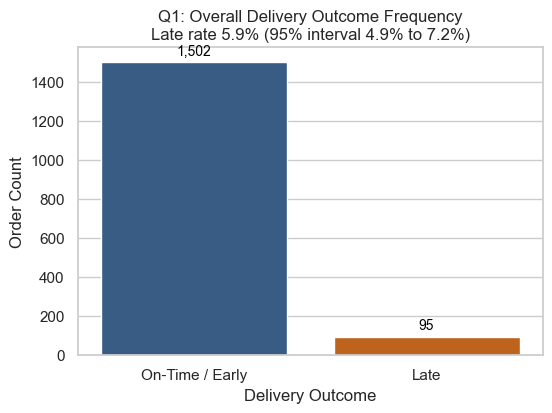

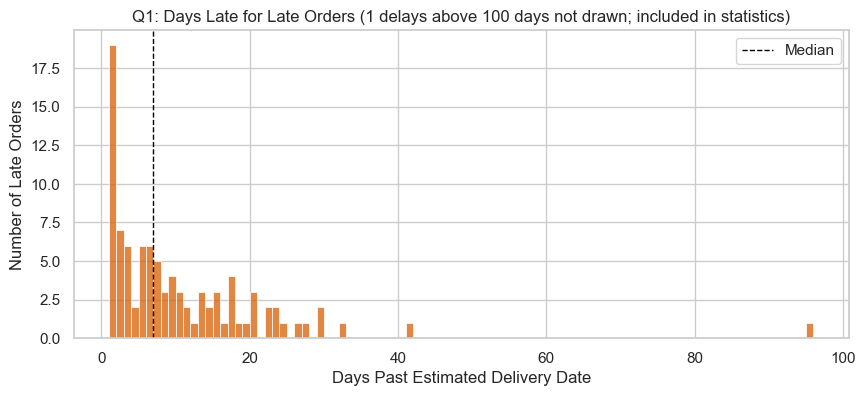

In [38]:
_t0 = start_step()
sns.set_theme(style="whitegrid")

print("Question 1: Frequency and Duration of Late Deliveries")

# 1. Overall frequency with a 95% Wilson interval
total_orders = len(df_labeled)
late_count = int(df_labeled[target_col].sum())
late_pct = (late_count / total_orders) * 100
rate_lo, rate_hi = wilson_ci(late_count, total_orders)

print(f"Total Labeled Usable Orders: {total_orders:,}")
print(f"Late Orders: {late_count:,} ({late_pct:.2f}%), 95% interval {rate_lo:.2%} to {rate_hi:.2%}")
print(f"On-Time / Early Orders: {total_orders - late_count:,} ({100 - late_pct:.2f}%)")

# 2. Delay duration in calendar days for late orders
df_labeled['delay_days'] = (
    df_labeled['order_delivered_customer_date'].dt.normalize() - df_labeled['order_estimated_delivery_date'].dt.normalize()
).dt.days

late_orders_df = df_labeled[df_labeled[target_col] == 1]
print("\n--- Delay Duration Statistics (Days Late) ---")
print(late_orders_df['delay_days'].describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95]))

delay = late_orders_df['delay_days']
delay_median, delay_q1, delay_q3 = delay.median(), delay.quantile(0.25), delay.quantile(0.75)
mean_lo, mean_hi = mean_ci(delay)
print(f"Median delay {delay_median:.0f} days (IQR {delay_q1:.0f} to {delay_q3:.0f} days)")
print(f"Mean delay {delay.mean():.1f} days (95% CI {mean_lo:.1f} to {mean_hi:.1f}, mean +/- 1.96 standard errors)")

# Severity bands: how many late orders are slightly vs severely late
delay_bands = pd.cut(late_orders_df['delay_days'], bins=[0, 3, 7, 14, 30, np.inf],
                     labels=['1-3 days', '4-7 days', '8-14 days', '15-30 days', '>30 days'])
delay_band_table = delay_bands.value_counts(sort=False).rename('Late_Orders').to_frame()
delay_band_table['Share_of_Late'] = (delay_band_table['Late_Orders'] / len(late_orders_df)).round(3)
display(delay_band_table)

# 3. Plot: outcome counts
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_labeled, x=target_col, hue=target_col,
                   palette=['#2b5c8f', '#d95f02'], legend=False)
plt.title(f'Q1: Overall Delivery Outcome Frequency\nLate rate {late_pct:.1f}% (95% interval {rate_lo:.1%} to {rate_hi:.1%})')
plt.xlabel('Delivery Outcome')
plt.ylabel('Order Count')
plt.xticks([0, 1], ['On-Time / Early', 'Late'])
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 3),
                    textcoords='offset points')
plt.show()

# 4. Plot: histogram of delay days, one bar per day; tail beyond the 99th percentile not drawn
q99 = late_orders_df['delay_days'].quantile(0.99)
n_tail = int((late_orders_df['delay_days'] > q99).sum())
plt.figure(figsize=(10, 4))
sns.histplot(late_orders_df.loc[late_orders_df['delay_days'] <= q99, 'delay_days'], binwidth=1, color='#d95f02')
plt.axvline(late_orders_df['delay_days'].median(), color='black', ls='--', lw=1, label='Median')
plt.title(f'Q1: Days Late for Late Orders ({n_tail} delays above {q99:.0f} days not drawn; included in statistics)')
plt.xlabel('Days Past Estimated Delivery Date')
plt.ylabel('Number of Late Orders')
plt.legend()
plt.show()
end_step('3 EDA Q1', _t0)


In [39]:
_pipeline_observer.end('09_eda_delivery', globals())

### 3.2 Question 2: Promised Window and Late Delivery

The promised window is the number of calendar days from approval to the estimated delivery date. The box plot compares windows by outcome; the band chart shows the late rate in each window band with 95% intervals, which reveals non-linear patterns a box plot hides. Each band's interval is compared with the overall rate, and the shortest band with all longer windows. Orders without an approval date are reported separately. Differences may reflect route and product mix; they do not prove that longer promises improve delivery.


In [40]:
_pipeline_observer.start('10_eda_window')

Question 2: Promised Window & Numerical Feature Distributions


,delivered_after_estimate,count,mean,median,std
0,On-Time / Early,1467,23.521472,23.0,8.785844
1,Late,92,23.282609,24.0,7.184119


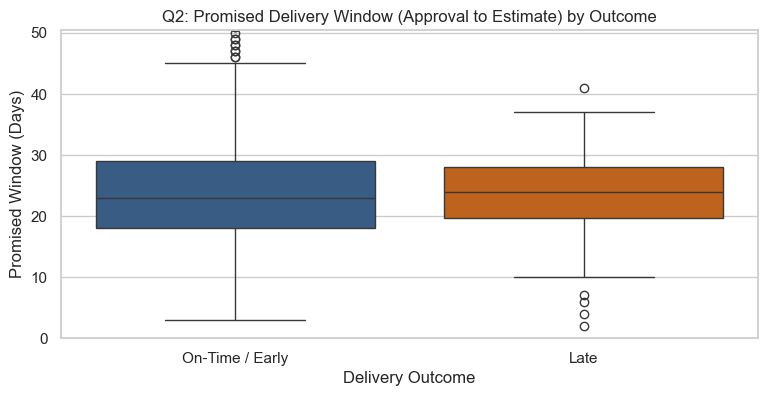

,window_band,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note
0,0-7,29,4.0,0.137931,NaN,NaN,too few events: interval suppressed
1,8-14,201,4.0,0.019900,NaN,NaN,too few events: interval suppressed
2,15-21,405,25.0,0.061728,0.042157,0.089536,
3,22-28,536,39.0,0.072761,0.053680,0.097923,
4,29+,388,20.0,0.051546,0.033613,0.078273,


Q2 window bands vs overall rate: 5 groups, overall rate 5.9%: 0 wholly above, 0 wholly below, 3 overlapping, 2 too small -> overlap: no clear difference


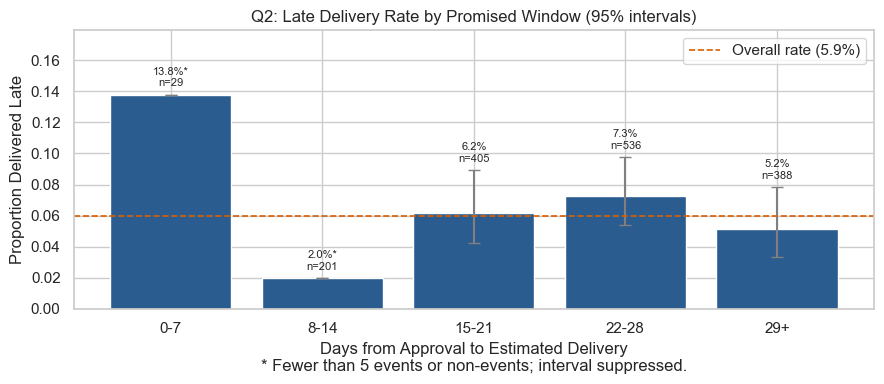

Q2 0-7 day window vs longer windows: 0-7 days 13.8% [5.5%, 30.6%], n=29 vs longer 5.8% [4.7%, 7.0%], n=1,530 -> overlap: no clear difference
Orders without an approval date are omitted from window comparisons: 38
Repaired basket price (BRL): 1,559 available of 1,597 reliable deliveries; log plot shows positives only.
Max product weight (g): 1,468 available of 1,597 reliable deliveries; log plot shows positives only.


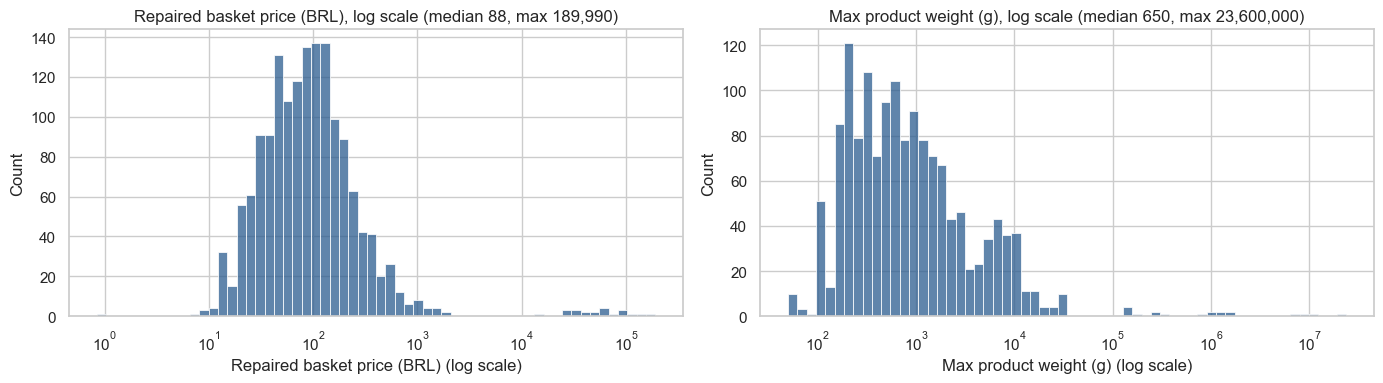

In [41]:
_t0 = start_step()
print("Question 2: Promised Window & Numerical Feature Distributions")

# 1. Promised window: calendar days between approval and estimated delivery
df_labeled['promised_window_days'] = (
    df_labeled['order_estimated_delivery_date'].dt.normalize() - df_labeled['order_approved_at'].dt.normalize()
).dt.days

window_summary = df_labeled.groupby(target_col)['promised_window_days'].agg(
    ['count', 'mean', 'median', 'std']
).reset_index()
window_summary[target_col] = window_summary[target_col].map({0: 'On-Time / Early', 1: 'Late'})
display(window_summary)

# 2. Plot: box plot of promised windows by outcome
plt.figure(figsize=(9, 4))
sns.boxplot(data=df_labeled, x=target_col, y='promised_window_days', hue=target_col,
            palette=['#2b5c8f', '#d95f02'], legend=False)
plt.title('Q2: Promised Delivery Window (Approval to Estimate) by Outcome')
plt.xlabel('Delivery Outcome')
plt.ylabel('Promised Window (Days)')
plt.xticks([0, 1], ['On-Time / Early', 'Late'])
plt.ylim(0, df_labeled['promised_window_days'].quantile(0.99))
plt.show()

# 3. Late rate by window band, with 95% Wilson intervals
df_labeled['window_band'] = pd.cut(df_labeled['promised_window_days'],
                                   bins=[-1, 7, 14, 21, 28, np.inf],
                                   labels=['0-7', '8-14', '15-21', '22-28', '29+'])
window_rates = rate_table(df_labeled[df_labeled['window_band'].notna()], 'window_band')
display(window_rates)
comparisons.append(compare_to_overall(window_rates, 'Q2 window bands vs overall rate'))
plot_rates(window_rates, 'window_band', 'Q2: Late Delivery Rate by Promised Window (95% intervals)',
           'Days from Approval to Estimated Delivery')

short = df_labeled['window_band'].eq('0-7')
known_window = df_labeled['window_band'].notna()
longer = known_window & ~short
window_comparison = pd.DataFrame([compare_rates(
    'Q2 0-7 day window vs longer windows',
    '0-7 days', df_labeled.loc[short, target_col].sum(), short.sum(),
    'longer', df_labeled.loc[longer, target_col].sum(), longer.sum())])
comparisons.append(window_comparison.iloc[0].to_dict())
df_labeled['window_band'] = df_labeled['window_band'].astype('string')
print("Orders without an approval date are omitted from window comparisons:",
      int(df_labeled['promised_window_days'].isna().sum()))

# 4. Skew check for price and weight on a log scale (extreme values otherwise hide the shape)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, label in zip(axes, ['basket_price_repaired', 'max_product_weight_g'],
                          ['Repaired basket price (BRL)', 'Max product weight (g)']):
    vals = df_labeled[col].dropna()
    print(f'{label}: {len(vals):,} available of {len(df_labeled):,} reliable deliveries; log plot shows positives only.')
    vals = vals[vals > 0]
    sns.histplot(vals, bins=60, log_scale=True, ax=ax, color='#2b5c8f')
    ax.set_title(f'{label}, log scale (median {vals.median():,.0f}, max {vals.max():,.0f})')
    ax.set_xlabel(f'{label} (log scale)')
plt.tight_layout()
plt.show()
end_step('3 EDA Q2', _t0)


In [42]:
_pipeline_observer.end('10_eda_window', globals())

### 3.3 Question 3: Late-Delivery Rates by Customer State

Review both late rates and late-order counts when choosing investigation priorities. Each state's rate has a 95% Wilson interval when there are at least five late and five on-time outcomes. Only those intervals support a descriptive above/below-national flag; sparse groups keep their rates with a warning. **Excess late orders** (late orders minus what the national rate predicts) combine rate and volume into one priority measure. States with fewer than 50 labelled orders are not ranked, and unknown states stay separate from the rankings. `state_sensitivity` shows how state rates change under other inclusion policies.


In [43]:
_pipeline_observer.start('11_eda_state')

Question 3: Late-Delivery Rates Across Customer States
Unknown customer geography (reported separately):


,customer_state,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note,Excess_Late,Vs_National
26,unknown,153,8.0,0.052288,0.02673,0.099778,,-1.1,not distinguishable


Q3 customer states (>= 50 orders) vs national rate: 6 groups, overall rate 5.9%: 1 wholly above, 1 wholly below, 2 overlapping, 2 too small -> gap: rates differ

Top 10 Customer States with Highest Late Delivery Rates (Min 50 Orders):


,customer_state,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note,Excess_Late,Vs_National
18,rj,191,22.0,0.115183,0.077306,0.168235,,10.6,above national
21,rs,74,5.0,0.067568,0.029204,0.148614,,0.6,not distinguishable
22,sc,53,3.0,0.056604,NaN,NaN,too few events: interval suppressed,-0.2,too few events
10,mg,171,8.0,0.046784,0.023894,0.089590,,-2.2,not distinguishable
24,sp,623,20.0,0.032103,0.020876,0.049065,,-17.1,below national
17,pr,70,1.0,0.014286,NaN,NaN,too few events: interval suppressed,-3.2,too few events



Top 10 Customer States with Lowest Late Delivery Rates (Min 50 Orders):


,customer_state,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note,Excess_Late,Vs_National
18,rj,191,22.0,0.115183,0.077306,0.168235,,10.6,above national
21,rs,74,5.0,0.067568,0.029204,0.148614,,0.6,not distinguishable
22,sc,53,3.0,0.056604,NaN,NaN,too few events: interval suppressed,-0.2,too few events
10,mg,171,8.0,0.046784,0.023894,0.089590,,-2.2,not distinguishable
24,sp,623,20.0,0.032103,0.020876,0.049065,,-17.1,below national
17,pr,70,1.0,0.014286,NaN,NaN,too few events: interval suppressed,-3.2,too few events



States whose whole 95% interval lies above the national rate:


,customer_state,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note,Excess_Late,Vs_National
18,rj,191,22.0,0.115183,0.077306,0.168235,,10.6,above national


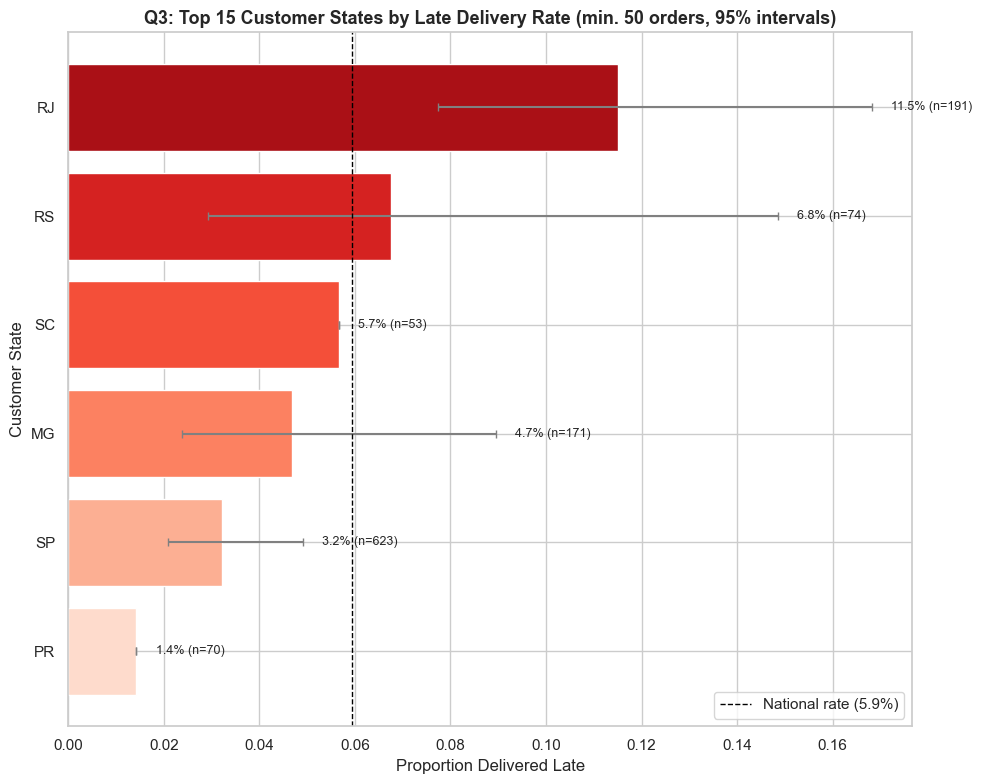

Investigation priority (most excess late orders):


,customer_state,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note,Excess_Late,Vs_National
18,rj,191,22.0,0.115183,0.077306,0.168235,,10.6,above national
21,rs,74,5.0,0.067568,0.029204,0.148614,,0.6,not distinguishable
22,sc,53,3.0,0.056604,NaN,NaN,too few events: interval suppressed,-0.2,too few events
10,mg,171,8.0,0.046784,0.023894,0.089590,,-2.2,not distinguishable
17,pr,70,1.0,0.014286,NaN,NaN,too few events: interval suppressed,-3.2,too few events


Late rate of priority states under each inclusion policy:


Policy,Complete original amounts,Dates present only (not reliable),"Main analysis, all item weights recorded","Main analysis, approval recorded",Main analysis: reliable outcomes,Repaired amounts: feature eligible
customer_state,,,,,,
mg,0.054,0.046,0.045,0.048,0.047,0.050
pr,0.015,0.013,0.016,0.015,0.014,0.015
rj,0.123,0.102,0.109,0.114,0.115,0.122
rs,0.057,0.062,0.072,0.055,0.068,0.068
sc,0.060,0.062,0.059,0.057,0.057,0.059
sp,0.033,0.031,0.032,0.031,0.032,0.033


In [44]:
_t0 = start_step()
print("Question 3: Late-Delivery Rates Across Customer States")
overall = df_labeled[target_col].mean()

# 1. Aggregate by customer state, with 95% Wilson intervals and excess late orders
state_perf = rate_table(df_labeled, 'customer_state')
state_perf['Excess_Late'] = (state_perf['Late_Orders'] - state_perf['Total_Orders'] * overall).round(1)
state_perf['Vs_National'] = np.select(
    [state_perf['CI_Lower'] > overall, state_perf['CI_Upper'] < overall],
    ['above national', 'below national'], default='not distinguishable')
state_perf.loc[state_perf['CI_Note'].ne(''), 'Vs_National'] = 'too few events'

print("Unknown customer geography (reported separately):")
display(state_perf[state_perf['customer_state'] == 'unknown'])

# 2. Rank valid states with at least 50 labelled orders
state_perf_filtered = state_perf[(state_perf['Total_Orders'] >= 50) &
                                 (state_perf['customer_state'] != 'unknown')].sort_values('Late_Rate', ascending=False)
comparisons.append(compare_to_overall(state_perf_filtered, 'Q3 customer states (>= 50 orders) vs national rate', overall))

print("\nTop 10 Customer States with Highest Late Delivery Rates (Min 50 Orders):")
display(state_perf_filtered.head(10))
print("\nTop 10 Customer States with Lowest Late Delivery Rates (Min 50 Orders):")
display(state_perf_filtered.tail(10))
print("\nStates whose whole 95% interval lies above the national rate:")
display(state_perf_filtered[state_perf_filtered['Vs_National'] == 'above national'])

# 3. Plot: top 15 states, darker = higher rate, with 95% intervals and the national rate
top_problem_states = state_perf_filtered.head(15).sort_values('Late_Rate')     # highest drawn at the top
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top_problem_states['customer_state'].str.upper(), top_problem_states['Late_Rate'],
        color=sns.color_palette('Reds', len(top_problem_states)),
        xerr=[(top_problem_states['Late_Rate'] - top_problem_states['CI_Lower']).fillna(0),
              (top_problem_states['CI_Upper'] - top_problem_states['Late_Rate']).fillna(0)],
        capsize=3, ecolor='grey')
ax.axvline(overall, ls='--', color='black', lw=1, label=f'National rate ({overall:.1%})')
for y, r in enumerate(top_problem_states.itertuples()):
    upper = r.CI_Upper if pd.notna(r.CI_Upper) else r.Late_Rate
    ax.text(upper + 0.004, y, f'{r.Late_Rate:.1%} (n={r.Total_Orders:,})', va='center', fontsize=9)
ax.set_title('Q3: Top 15 Customer States by Late Delivery Rate (min. 50 orders, 95% intervals)',
             fontsize=13, weight='bold')
ax.set_xlabel('Proportion Delivered Late'); ax.set_ylabel('Customer State'); ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 4. Investigation priority: excess late orders combine rate and volume
print("Investigation priority (most excess late orders):")
display(state_perf_filtered.sort_values('Excess_Late', ascending=False).head(5))

# 5. Sensitivity of state rates to the inclusion policy
priority_states = state_perf_filtered.sort_values('Excess_Late', ascending=False).head(8)['customer_state']
print("Late rate of priority states under each inclusion policy:")
display(state_sensitivity[state_sensitivity['customer_state'].isin(priority_states)]
        .pivot(index='customer_state', columns='Policy', values='mean').round(3))
end_step('3 EDA Q3', _t0)


In [45]:
_pipeline_observer.end('11_eda_state', globals())

### 3.4 Additional Hypotheses: Photos, Payments, and Local Fulfillment

**Photos (scam hypothesis).** Listings with few photos may signal low-effort or fraudulent sellers, who might ship late. A scam is more likely to end in non-delivery than in a late delivery, so non-delivery by photo band is also described across all orders (descriptive only; status is never a predictor).
**Payment type.** Boleto payments clear more slowly and could delay dispatch. Selected payment type is the alphabetically last type for an order, not necessarily its dominant payment, and payment fields never enter the predictor matrix.
**Local vs cross-state sellers.** Out-of-state shipments involve longer distances and more carrier hand-offs. Unknown fulfillment geography is reported explicitly and excluded from the comparison.

Eligible rates have 95% Wilson intervals; groups with fewer than five events or non-events have their intervals suppressed. Groups are compared through their intervals. These are descriptive associations, not causal effects.


In [46]:
_pipeline_observer.start('12_eda_hypotheses')

=== Custom Hypotheses: Photos, Payment Methods, & Local Fulfillment ===

--- 1. Product Photo Quantity Analysis ---


,max_product_photos,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note
0,1,678,41.0,0.060472,0.044886,0.081010,
1,2,293,13.0,0.044369,0.026110,0.074421,
2,3,181,7.0,0.038674,0.018858,0.077666,
3,4,116,3.0,0.025862,NaN,NaN,too few events: interval suppressed
4,5,78,13.0,0.166667,0.100069,0.264558,
5,6,50,4.0,0.080000,NaN,NaN,too few events: interval suppressed
6,7,23,2.0,0.086957,NaN,NaN,too few events: interval suppressed
7,8,13,1.0,0.076923,NaN,NaN,too few events: interval suppressed
8,9,2,0.0,0.000000,NaN,NaN,too few events: interval suppressed
9,10,3,0.0,0.000000,NaN,NaN,too few events: interval suppressed


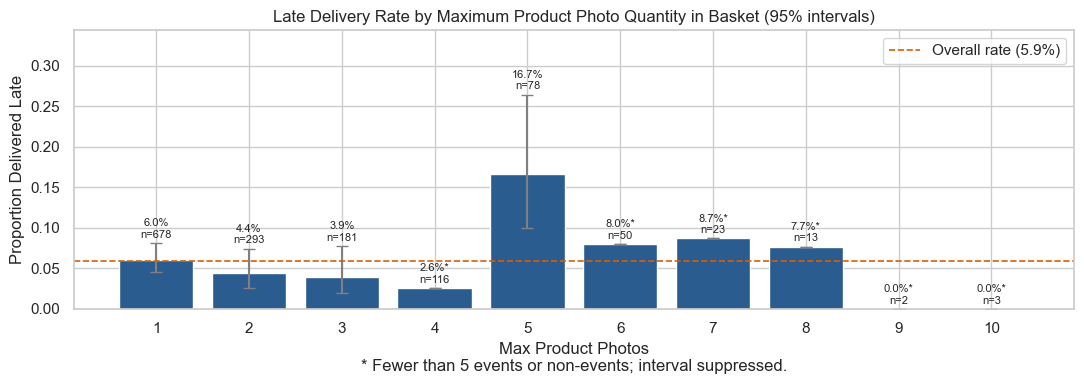

,photo_band,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note
0,1-2,971,54.0,0.055613,0.042871,0.071857,
1,3-5,375,23.0,0.061333,0.041214,0.090350,
2,6+,94,7.0,0.074468,0.036538,0.145814,


H1 photo bands (1-2 / 3-5 / 6+) vs overall late rate: 3 groups, overall rate 5.8%: 0 wholly above, 0 wholly below, 3 overlapping, 0 too small -> overlap: no clear difference
Non-delivery rate by photo band (all orders; descriptive only):


,photo_band,Total_Orders,Not_Delivered,Not_Delivered_Rate,CI_Lower,CI_Upper,CI_Note
0,1-2,1202,113,0.094010,0.078780,0.111827,
1,3-5,471,47,0.099788,0.075873,0.130178,
2,6+,121,12,0.099174,0.057645,0.165371,


H1 photo bands vs overall NON-delivery rate (all orders): 3 groups, overall rate 9.6%: 0 wholly above, 0 wholly below, 3 overlapping, 0 too small -> overlap: no clear difference

--- 2. Selected Payment Type Analysis ---


,selected_payment_type,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note
0,boleto,300,22.0,0.073333,0.048924,0.108532,
4,voucher,60,4.0,0.066667,NaN,NaN,too few events: interval suppressed
1,credit_card,1144,66.0,0.057692,0.045603,0.072742,
2,debit_card,29,1.0,0.034483,NaN,NaN,too few events: interval suppressed
3,unclassified_payment,64,2.0,0.031250,NaN,NaN,too few events: interval suppressed


H2 payment types vs overall late rate: 5 groups, overall rate 5.9%: 0 wholly above, 0 wholly below, 2 overlapping, 3 too small -> overlap: no clear difference


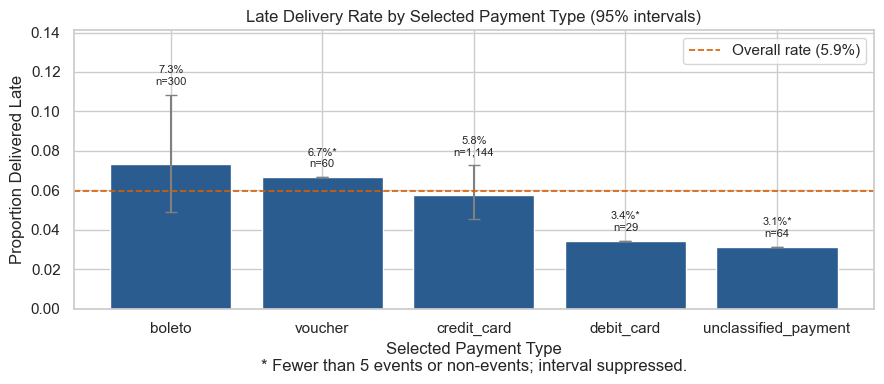


--- 3. Local Seller vs Cross-State Fulfillment Analysis ---


,fulfilment,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note
0,Unknown Geography,290,17.0,0.058621,0.036918,0.091864,
1,Cross-State Only,817,62.0,0.075887,0.059647,0.096097,
2,Involves Local Seller,490,16.0,0.032653,0.020197,0.052380,


H3 cross-state only vs involves local seller: cross-state only 7.6% [6.0%, 9.6%], n=817 vs local seller 3.3% [2.0%, 5.2%], n=490 -> gap: rates differ


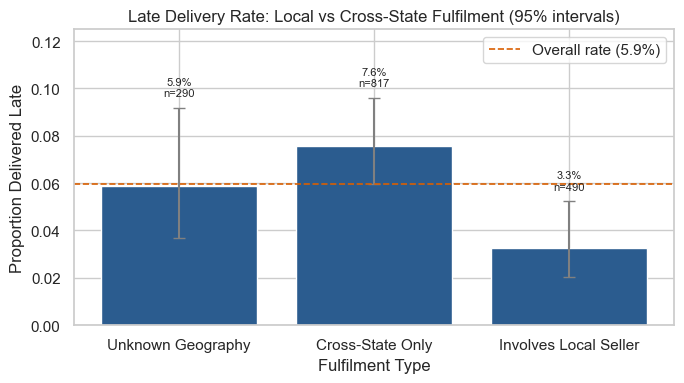

In [47]:
_t0 = start_step()
print("=== Custom Hypotheses: Photos, Payment Methods, & Local Fulfillment ===")

# 1. Photos: individual counts (1-10) and grouped bands
print("\n--- 1. Product Photo Quantity Analysis ---")
photo_grouped = rate_table(df_labeled[df_labeled['max_product_photos'] <= 10], 'max_product_photos')
photo_grouped['max_product_photos'] = photo_grouped['max_product_photos'].astype('Int64')
display(photo_grouped)
plot_rates(photo_grouped, 'max_product_photos',
           'Late Delivery Rate by Maximum Product Photo Quantity in Basket (95% intervals)',
           'Max Product Photos', figsize=(11, 4))

df_labeled['photo_band'] = pd.cut(df_labeled['max_product_photos'], [0, 2, 5, np.inf],
                                  labels=['1-2', '3-5', '6+'])
photo_band_rates = rate_table(df_labeled[df_labeled['photo_band'].notna()], 'photo_band')
display(photo_band_rates)
comparisons.append(compare_to_overall(photo_band_rates, 'H1 photo bands (1-2 / 3-5 / 6+) vs overall late rate'))

# Wider view of the scam idea: non-delivery among ALL orders (unlabelled outcomes included)
photo_band_all = pd.cut(df_clean['max_product_photos'], [0, 2, 5, np.inf], labels=['1-2', '3-5', '6+'])
nd = pd.DataFrame({'photo_band': photo_band_all,
                   'not_delivered': (~df_clean['order_status'].eq('delivered').fillna(False)).astype(int)})
nondelivery_rates = rate_table(nd[nd['photo_band'].notna()], 'photo_band', label_col='not_delivered')
nondelivery_rates = nondelivery_rates.rename(columns={'Late_Orders': 'Not_Delivered',
                                                      'Late_Rate': 'Not_Delivered_Rate'})
print("Non-delivery rate by photo band (all orders; descriptive only):")
display(nondelivery_rates)
comparisons.append(compare_to_overall(nondelivery_rates.rename(columns={'Not_Delivered': 'Late_Orders'}),
                                      'H1 photo bands vs overall NON-delivery rate (all orders)'))
df_labeled['photo_band'] = df_labeled['photo_band'].astype('string')

# 2. Payment type
print("\n--- 2. Selected Payment Type Analysis ---")
payment_grouped = rate_table(df_labeled, 'selected_payment_type').sort_values('Late_Rate', ascending=False)
display(payment_grouped)
comparisons.append(compare_to_overall(payment_grouped, 'H2 payment types vs overall late rate'))
plot_rates(payment_grouped, 'selected_payment_type',
           'Late Delivery Rate by Selected Payment Type (95% intervals)', 'Selected Payment Type')

# 3. Local seller vs cross-state only
print("\n--- 3. Local Seller vs Cross-State Fulfillment Analysis ---")
local_labels = {-1: 'Unknown Geography', 0: 'Cross-State Only', 1: 'Involves Local Seller'}
local_grouped = rate_table(df_labeled.assign(fulfilment=df_labeled['involves_local_seller'].fillna(-1)), 'fulfilment')
local_grouped['fulfilment'] = local_grouped['fulfilment'].map(local_labels)
display(local_grouped)
known_geo = local_grouped[local_grouped['fulfilment'] != 'Unknown Geography']
cross = known_geo.set_index('fulfilment').loc['Cross-State Only']
local = known_geo.set_index('fulfilment').loc['Involves Local Seller']
local_comparison = pd.DataFrame([compare_rates(
    'H3 cross-state only vs involves local seller',
    'cross-state only', cross['Late_Orders'], cross['Total_Orders'],
    'local seller', local['Late_Orders'], local['Total_Orders'])])
comparisons.append(local_comparison.iloc[0].to_dict())
plot_rates(local_grouped, 'fulfilment', 'Late Delivery Rate: Local vs Cross-State Fulfilment (95% intervals)',
           'Fulfilment Type', figsize=(7, 4))
end_step('3 EDA hypotheses', _t0)


In [48]:
_pipeline_observer.end('12_eda_hypotheses', globals())

### 3.5 Product Weight and Delay Duration

Weight is heavily right-skewed, so it is compared on a log scale. The Pearson correlation between log weight and days late is checked with a scatterplot.


In [49]:
_pipeline_observer.start('13_eda_weight')

=== Bivariate Exploratory Analysis: Product Weight vs. Delay Duration (Cleaned View) ===
Pearson r, log10(max weight) vs days late (all 86 late orders with a weight): r = -0.017


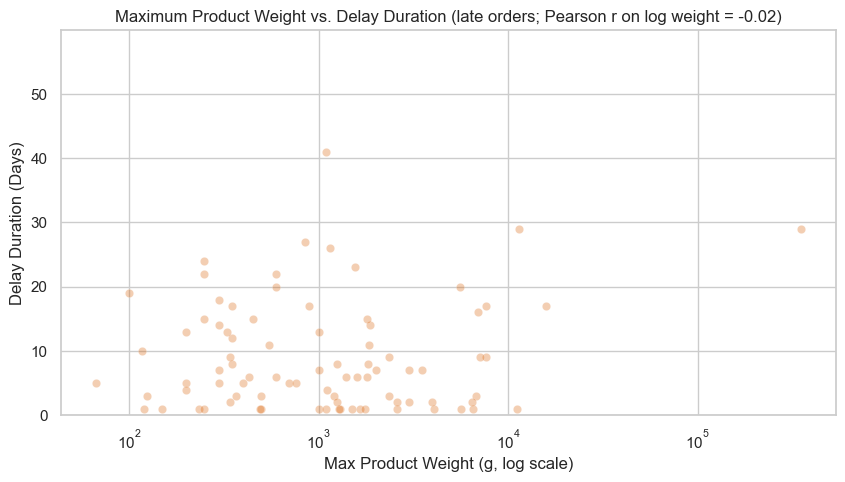

In [50]:
_t0 = start_step()
print("=== Bivariate Exploratory Analysis: Product Weight vs. Delay Duration (Cleaned View) ===")

late_with_weight = df_labeled[(df_labeled[target_col] == 1) & df_labeled['max_product_weight_g'].notna()]
# Pearson r on log weight: the log folds in the heavy tail so a few huge weights cannot dominate r
r = np.log10(late_with_weight['max_product_weight_g']).corr(late_with_weight['delay_days'])
print(f"Pearson r, log10(max weight) vs days late (all {len(late_with_weight):,} late orders "
      f"with a weight): r = {r:.3f}")
comparisons.append({'Comparison': 'H5 log weight vs days late (late orders)',
                    'Result': f'Pearson r = {r:.3f}, n = {len(late_with_weight):,}',
                    'Finding': 'r close to zero: no clear relationship' if abs(r) < 0.1 else f'r = {r:.2f}: check the scatterplot'})

# Scatterplot of every late order with a weight; weight on a log axis, days late shown up to the 99th percentile
scatter_df = late_with_weight.copy()
plt.figure(figsize=(10, 5))
sns.scatterplot(data=scatter_df, x='max_product_weight_g', y='delay_days', alpha=0.3, color='#d95f02')
plt.xscale('log')
plt.title(f'Maximum Product Weight vs. Delay Duration (late orders; Pearson r on log weight = {r:.2f})')
plt.xlabel('Max Product Weight (g, log scale)')
plt.ylabel('Delay Duration (Days)')
plt.ylim(0, scatter_df['delay_days'].quantile(0.99))
plt.show()
end_step('3 EDA weight', _t0)


In [51]:
_pipeline_observer.end('13_eda_weight', globals())

### 3.6 Seller and Geographic Complexity

In [52]:
_pipeline_observer.start('14_eda_sellers')

Exploratory Analysis: Multi-Seller & Multi-State Sourcing vs. Late Delivery

Late Delivery Rate by Number of Unique Sellers:


,total_unique_sellers,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note
0,1,1567,95.0,0.060625,0.04985,0.07355,
1,2,29,0.0,0.000000,NaN,NaN,too few events: interval suppressed
2,3,1,0.0,0.000000,NaN,NaN,too few events: interval suppressed


H4 2 sellers vs 1 seller: 2 sellers 0.0% [0.0%, 11.7%], n=29 vs 1 seller 6.1% [5.0%, 7.4%], n=1,567 -> overlap: no clear difference

Late Delivery Rate by Unique Seller States (0 = unknown seller state):


,total_unique_seller_states,Total_Orders,Late_Orders,Late_Rate,CI_Lower,CI_Upper,CI_Note
0,0.0,146,10.0,0.068493,0.037626,0.121486,
1,1.0,1442,85.0,0.058946,0.047921,0.072315,
2,2.0,9,0.0,0.000000,NaN,NaN,too few events: interval suppressed


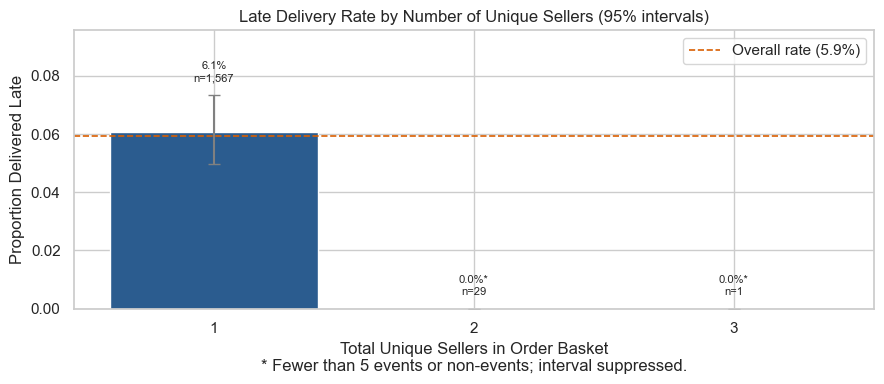


Summary of comparisons (gap = rates differ; overlap = no clear difference):


,Comparison,Result,Finding
0,Q2 window bands vs overall rate,"5 groups, overall rate 5.9%: 0 wholly above, 0...",overlap: no clear difference
1,Q2 0-7 day window vs longer windows,"0-7 days 13.8% [5.5%, 30.6%], n=29 vs longer 5...",overlap: no clear difference
2,Q3 customer states (>= 50 orders) vs national ...,"6 groups, overall rate 5.9%: 1 wholly above, 1...",gap: rates differ
3,H1 photo bands (1-2 / 3-5 / 6+) vs overall lat...,"3 groups, overall rate 5.8%: 0 wholly above, 0...",overlap: no clear difference
4,H1 photo bands vs overall NON-delivery rate (a...,"3 groups, overall rate 9.6%: 0 wholly above, 0...",overlap: no clear difference
5,H2 payment types vs overall late rate,"5 groups, overall rate 5.9%: 0 wholly above, 0...",overlap: no clear difference
6,H3 cross-state only vs involves local seller,"cross-state only 7.6% [6.0%, 9.6%], n=817 vs l...",gap: rates differ
7,H5 log weight vs days late (late orders),"Pearson r = -0.017, n = 86",r close to zero: no clear relationship
8,H4 2 sellers vs 1 seller,"2 sellers 0.0% [0.0%, 11.7%], n=29 vs 1 seller...",overlap: no clear difference


In [53]:
_t0 = start_step()
print("Exploratory Analysis: Multi-Seller & Multi-State Sourcing vs. Late Delivery")

# 1. Late rate by number of unique sellers
seller_analysis = rate_table(df_labeled, 'total_unique_sellers')
seller_analysis['total_unique_sellers'] = seller_analysis['total_unique_sellers'].astype('Int64')
print("\nLate Delivery Rate by Number of Unique Sellers:")
display(seller_analysis)

# Compare 2-seller with 1-seller orders through their 95% intervals
one = df_labeled['total_unique_sellers'].eq(1)
two = df_labeled['total_unique_sellers'].eq(2)
seller_comparison = pd.DataFrame([compare_rates(
    'H4 2 sellers vs 1 seller',
    '2 sellers', df_labeled.loc[two, target_col].sum(), two.sum(),
    '1 seller', df_labeled.loc[one, target_col].sum(), one.sum())])
comparisons.append(seller_comparison.iloc[0].to_dict())

# 2. Late rate by number of distinct valid seller states (0 = seller state unknown)
state_seller_analysis = rate_table(df_labeled, 'total_unique_seller_states')
print("\nLate Delivery Rate by Unique Seller States (0 = unknown seller state):")
display(state_seller_analysis)

# 3. Plot
plot_rates(seller_analysis, 'total_unique_sellers',
           'Late Delivery Rate by Number of Unique Sellers (95% intervals)', 'Total Unique Sellers in Order Basket')

# 4. Summary of all interval comparisons in Part 3
comparison_summary = pd.DataFrame(comparisons)
print("\nSummary of comparisons (gap = rates differ; overlap = no clear difference):")
display(comparison_summary)
end_step('3 EDA sellers + comparison summary', _t0)


In [54]:
_pipeline_observer.end('14_eda_sellers', globals())

<a id="part-4"></a>

## Part 4: Feature Engineering

Prepare approval-time features and a numerical feature matrix with matching labels and order IDs.

### 4.1 Approval-Time Features and State Encoding

Select financially complete orders, derive approval-time fields, and encode customer states. The numerical feature matrix is built **once** in Section 4.2.


In [55]:
_pipeline_observer.start('15_initial_features')

In [56]:
_t0 = start_step()
print("PART 4: FEATURE ENGINEERING & PIPELINE SETUP")

# Keep only financially complete orders in the feature dataset.
df_features = df_labeled.loc[feature_eligible_mask.loc[df_labeled.index]].copy()

# Approval-time features
df_features['approval_hour'] = df_features['order_approved_at'].dt.hour
df_features['approval_dayofweek'] = df_features['order_approved_at'].dt.dayofweek
df_features['is_weekend_approval'] = df_features['approval_dayofweek'].isin([5, 6]).astype(float)
df_features.loc[df_features['order_approved_at'].isna(), 'is_weekend_approval'] = np.nan

# Fixed state vocabulary, including unknown states.
state_categories = pd.Categorical(df_features['customer_state'], categories=valid_states + ['unknown'])
df_encoded = pd.get_dummies(
    pd.Series(state_categories, index=df_features.index), prefix='customer_state', dtype=int)

print(f'Feature-eligible orders: {len(df_features):,}')
end_step('4 Initial features', _t0)


PART 4: FEATURE ENGINEERING & PIPELINE SETUP
Feature-eligible orders: 1,527


In [57]:
_pipeline_observer.end('15_initial_features', globals())

### 4.2 Final Feature Matrix

Add logarithmic transformations and domain ratios, handle missing numerical values, and keep the full feature table, labels and order IDs separate.

The weight feature is the mean of item weights, available only when every item weight is recorded. Zero-price baskets keep their valid prices; their undefined freight/price ratio is marked missing. Unknown maximum photo counts use zero as a numerical placeholder, with missing-photo flags retained. Other missing features use the full prepared dataset medians and retain their missing indicators. State encoding uses the fixed 27-state vocabulary plus `unknown`.

This assignment prepares one dataset. For future model evaluation, split first and estimate both item-matching medians and predictor-fill medians using training data only. Rebuild item repairs from original amounts: `X_unfilled` already contains full-dataset item repairs.


In [58]:
_pipeline_observer.start('16_final_features')

In [59]:
_t0 = start_step()
print("PART 4: FEATURE ENGINEERING & FINAL DATASET")

# 1. Reuse the audited data and approval-time features
df_pipeline = df_features.copy()

# 2. Engineer Domain Ratios and Transformations
df_pipeline['log_basket_price'] = np.log1p(df_pipeline['basket_price_repaired'])
df_pipeline['log_freight'] = np.log1p(df_pipeline['total_freight_repaired'])
df_pipeline['freight_to_price_ratio'] = df_pipeline['total_freight_repaired'] / df_pipeline['basket_price_repaired'].replace(0, np.nan)
df_pipeline['seller_complexity_ratio'] = df_pipeline['total_unique_sellers'] / df_pipeline['total_items']

# 3. Keep only numerical features that are available at approval time
numeric_feature_cols = [
    'total_items', 'basket_price_repaired', 'total_freight_repaired',
    'log_basket_price', 'log_freight', 'freight_to_price_ratio',
    'mean_product_weight_g', 'seller_complexity_ratio',
    'total_unique_sellers', 'total_unique_seller_states',
    'max_product_weight_g', 'max_product_photos',
    'involves_local_seller', 'promised_window_days',
    'approval_hour', 'is_weekend_approval',
    'product_weight_missing', 'product_photos_missing'
]
# Keep the existing predictor names; originals remain in df_pipeline for auditing.
X_numeric = df_pipeline[numeric_feature_cols].rename(columns={
    'basket_price_repaired': 'basket_price', 'total_freight_repaired': 'total_freight'}).astype(float).copy()
numeric_feature_cols = X_numeric.columns.tolist()
# Missing indicators preserve which values were originally unknown. They are added only for
# features that can actually be missing, and never for columns that are already missing flags.
for col in numeric_feature_cols:
    if X_numeric[col].isna().any() and not col.endswith('_missing'):
        X_numeric[col + '_missing'] = X_numeric[col].isna().astype(int)
print("Missing indicators added for:", [c for c in X_numeric.columns if c.endswith('_missing')
                                        and c not in numeric_feature_cols])
X_categorical = df_encoded.copy()
X_unfilled = pd.concat([X_numeric, X_categorical], axis=1)
y = df_pipeline[target_col].astype(int)
order_ids = df_pipeline['order_id']

# 4. Fill Missing Values: Zero for Unknown Photos, Medians for Other Features
feature_medians = X_unfilled.median().fillna(0)
feature_medians['max_product_photos'] = 0  # Placeholder; missing-photo flags remain.
imputation_values = feature_medians.rename('fill_value').rename_axis('feature').reset_index()
X = X_unfilled.fillna(feature_medians)

# 5. Check the Full Feature Table, Labels and IDs
assert np.isfinite(X.to_numpy()).all()
assert X.index.equals(y.index) and X.index.equals(order_ids.index)
assert order_ids.is_unique
assert len(X) == int(feature_eligible_mask.sum())
assert order_ids.equals(df_clean.loc[feature_eligible_mask, 'order_id'])
assert y.equals(df_clean.loc[feature_eligible_mask, target_col].astype(int))
assert df_pipeline[['basket_price_repaired', 'total_freight_repaired']].ge(0).all().all()
assert not (no_items_mask | unresolved_amount_mask).loc[X.index].any()
forbidden = ['payment', 'status', 'review', 'shipping_limit', 'delivered_', 'order_id', 'customer_id']
assert not any(any(term in col for term in forbidden) for col in X.columns)
print(f"Final Feature Matrix Shape: {X.shape}")
print(f"Target Vector Shape: {y.shape}")
print(f"Order IDs: {len(order_ids):,}")
print("Missing feature values:", int(X.isna().sum().sum()))
end_step('4 Final features', _t0)


PART 4: FEATURE ENGINEERING & FINAL DATASET
Missing indicators added for: ['mean_product_weight_g_missing', 'max_product_weight_g_missing', 'max_product_photos_missing', 'involves_local_seller_missing', 'promised_window_days_missing', 'approval_hour_missing', 'is_weekend_approval_missing']
Final Feature Matrix Shape: (1527, 53)
Target Vector Shape: (1527,)
Order IDs: 1,527
Missing feature values: 0


In [60]:
_pipeline_observer.end('16_final_features', globals())

<a id="resources"></a>

## Resource Summary

Measured runtime and peak traced Python memory per step (`tracemalloc` counts Python and NumPy allocations, not SQLite's internal C memory), in-memory size of each main table, disk sizes, and the software environment.

In [61]:
_pipeline_observer.start('17_resources')

In [62]:
import sys, platform, glob
resource_df = pd.DataFrame(resource_log)
display(resource_df)

objects = {'master_orders (assembled)': master_orders, 'source_items (item level)': source_items,
           'df_clean (all orders, cleaned)': df_clean, 'df_labeled (labelled cohort)': df_labeled,
           'X_unfilled (features before fill)': X_unfilled, 'X (final features)': X}
object_sizes = pd.DataFrame([{'Object': k, 'Rows': len(v), 'Columns': v.shape[1],
                       'In-memory MiB (deep)': round(v.memory_usage(deep=True).sum() / 2**20, 2)}
                      for k, v in objects.items()])
display(object_sizes)

for f in ['data/raw.sql', db_path]:
    if os.path.exists(f):
        print(f"{f}: {os.path.getsize(f) / 2**20:.2f} MiB on disk")
out_dir = 'outputs/assignment1'
if os.path.exists(out_dir):
    size = sum(os.path.getsize(p) for p in glob.glob(f'{out_dir}/**/*', recursive=True) if os.path.isfile(p))
    print(f"{out_dir}: {size / 2**20:.2f} MiB of saved outputs")

import matplotlib, scipy
print("Python", sys.version.split()[0], "|", platform.platform())
for m in [pd, np, matplotlib, sns, scipy]:
    print(f"{m.__name__} {m.__version__}")

,Step,Runtime_s,Peak_traced_MiB
0,1 Assemble (SQL push-down),0.028,3.49
1,2 Clean + label,0.625,4.54
2,3 EDA Q1,0.622,2.87
3,3 EDA Q2,2.135,8.48
4,3 EDA Q3,0.381,1.11
5,3 EDA hypotheses,0.937,2.71
6,3 EDA weight,0.468,2.97
7,3 EDA sellers + comparison summary,0.245,0.82
8,4 Initial features,0.007,1.24
9,4 Final features,0.024,2.08


,Object,Rows,Columns,In-memory MiB (deep)
0,master_orders (assembled),2000,25,2.08
1,source_items (item level),2270,23,0.98
2,"df_clean (all orders, cleaned)",2000,37,1.79
3,df_labeled (labelled cohort),1597,41,1.64
4,X_unfilled (features before fill),1527,53,0.63
5,X (final features),1527,53,0.63


marketplace.sqlite: 2.08 MiB on disk
Python 3.11.15 | macOS-15.8.1-arm64-arm-64bit
pandas 3.0.1
numpy 2.4.3
matplotlib 3.10.8
seaborn 0.13.2
scipy 1.17.1


In [63]:
_pipeline_observer.end('17_resources', globals())

In [64]:
_pipeline_observer.finish()